# Proyecto Final – Modelación Predictiva en Analítica de Datos (Laboratorio # 3)
**Especialización en Analítica Estratégica de Datos · Estadística para Analítica de Datos · UPTC (2026-2)**  
**Profesor:** Duván Cataño  
**Integrantes:** Juan Beltrán · Daniel Castellanos · Daniel Rico  
**Base de datos:** Resultados únicos Saber 11 (ICFES) – Datos Abiertos de Colombia (`kgxf-xxbe`, periodo `20224`)  

---

### Contenido del Notebook (Estructura Oficial de la Guía)
1. **Introducción y objetivo:** Contexto del problema, continuidad con los Laboratorios 1 y 2, pregunta de analítica y objetivos de modelación.
2. **Descripción de variables:** Diccionario estadístico de variables originales y derivadas, roles en el modelo y control de fuga de información (*data leakage*).
3. **Limpieza y preprocesamiento:** Depuración de duplicados por `estu_consecutivo`, análisis del mecanismo **MNAR (*Missing Not At Random*)** en el cuestionario socioeconómico y experimento comparativo de métodos de imputación numérica (`SimpleImputer`, `KNNImputer`, `IterativeImputer` MICE).
4. **Análisis exploratorio de datos (EDA):** Medidas estructurales (tendencia central, dispersión, posición), medidas de forma (asimetría y curtosis), impacto de valores atípicos por criterio $1{,}5\cdot\text{IQR}$ y análisis bivariado.
5. **Pruebas de hipótesis e interpretación:** Pruebas paramétricas y no paramétricas de correlación (Pearson, Spearman, Kendall), independencia categórica ($\chi^2$, $V$ de Cramér, Información Mutua) y comparación de grupos (Levene, Bartlett, ANOVA de un factor, ANOVA de Welch y Kruskal-Wallis con tamaños de efecto $\eta^2$, $\omega^2$ y $\varepsilon^2$).
6. **Construcción de pipelines:** Diseño modular con `Pipeline` y `ColumnTransformer`, codificación *Dummy* ($k-1$) vs *One-Hot* ($k$), estandarización $Z$-score (`StandardScaler`) vs normalización Min-Max (`MinMaxScaler`) y demostración matemática del impacto del escalamiento sobre distancias euclidianas.
7. **Entrenamiento de modelos:** Ajuste de modelos de **Regresión Lineal Múltiple** (predicción continua de `punt_global`) y **Regresión Logística** (clasificación binaria de `supera_promedio` $\ge 250$), con validación cruzada ($k=10$) y optimización de hiperparámetros (`RandomizedSearchCV`).
8. **Evaluación del modelo:** Evaluación en conjunto de prueba para Regresión (**MAE, RMSE, MAPE y $R^2$**, más $R^2_{\text{ajustado}}$, RSE e inferencia econométrica MCO en `statsmodels` con pruebas de **Jarque-Bera**, **Breusch-Pagan**, **VIF** y errores robustos **HC3**) y para Clasificación (**Accuracy, Precision, Recall y F1-score**, más **ROC-AUC**, Matriz de Confusión, Curva ROC y *Odds Ratios* $e^{\beta_j}$).
9. **Conclusiones:** Síntesis ejecutiva de hallazgos, implicaciones de política educativa y articulación con la aplicación interactiva en **Streamlit**.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")

RAIZ = Path.cwd()
if not (RAIZ / "src").exists() and (RAIZ.parent / "src").exists():
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

from src import datos, estadistica as E, graficos as G, modelos as M

pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
%matplotlib inline

RUTA_FIG = RAIZ / "figuras"
RUTA_FIG.mkdir(exist_ok=True)

def md_(texto: str):
    display(Markdown(texto))

---
## 1. Introducción y Objetivo

### 1.1 Contexto y Relevancia del Problema
El examen de Estado **Saber 11**, aplicado por el **Instituto Colombiano para la Evaluación de la Educación (ICFES)**, constituye el principal instrumento estandarizado de medición de la calidad de la educación media en Colombia. Su resultado determina el acceso a la educación superior, la asignación de becas y créditos condonables, y la evaluación institucional de los establecimientos educativos.

Este proyecto final (**Laboratorio 3**) culmina la línea de investigación desarrollada en los **Laboratorios 1 y 2** sobre la cohorte **2022-2 (`periodo = 20224`)**:
- En el **Laboratorio 1** se estructuró la extracción reproducible desde la API Socrata de Datos Abiertos (`kgxf-xxbe`, muestra aleatoria de $80.000$ registros con `random_state=42`), se identificó la duplicación operacional en la fuente ($2.173$ filas repetidas) y se demostró que los valores ausentes en las variables de contexto familiar no ocurren al azar (**MNAR**).
- En el **Laboratorio 2** se realizó el análisis exploratorio profundo y la contrastación de hipótesis estadísticas, comprobando que el capital educativo del hogar (`fami_educacionmadre`, $\varepsilon^2 = 0.1275$) y la conectividad digital (`fami_tieneinternet`, $\varepsilon^2 = 0.0795$) son los factores estructurales que más diferencian el rendimiento académico.
- En este **Laboratorio 3** se lleva dicho diagnóstico hacia la **modelación predictiva e inferencial**, implementando flujos automatizados mediante `Pipeline` y `ColumnTransformer`, escalamiento de variables, modelos de **Regresión Lineal** y **Regresión Logística**, validación cruzada, diagnóstico de supuestos econométricos y despliegue en una aplicación interactiva en **Streamlit**.

### 1.2 Pregunta de Investigación y Objetivos de Modelación
> **Pregunta central:** *¿En qué medida es posible predecir el puntaje global del examen Saber 11 (regresión continua) y la probabilidad de superar el umbral nacional de 250 puntos (clasificación binaria) a partir de las condiciones socioeconómicas, familiares e institucionales del estudiante, y cómo cambia la capacidad predictiva al incorporar una competencia transversal observada?*

- **Objetivo General:** Desarrollar, validar y desplegar pipelines predictivos de **Regresión Lineal** y **Regresión Logística** sobre los resultados del examen Saber 11 (periodo 20224), integrando EDA, pruebas de hipótesis, imputación, codificación y escalamiento en una arquitectura reproducible con interfaz interactiva en Streamlit.
- **Objetivos Específicos:**
  1. Ejecutar el protocolo de limpieza e ingeniería de características evitando toda fuga de información (*data leakage*) y preservando la señal informativa de los datos ausentes del cuestionario socioeconómico.
  2. Sustentar estadísticamente la selección y transformación de variables mediante medidas de forma, análisis de atípicos IQR y pruebas de hipótesis paramétricas y no paramétricas.
  3. Construir y comparar dos especificaciones de `Pipeline` + `ColumnTransformer` tanto en **Regresión Lineal** (métricas **MAE, RMSE, MAPE y $R^2$**, más diagnóstico MCO en `statsmodels`) como en **Regresión Logística** (métricas **Accuracy, Precision, Recall y F1-score**, más **ROC-AUC** y *Odds Ratios*):
     - **Modelo A (Contexto Socioeconómico Puro — Modelo Principal):** Utiliza exclusivamente variables familiares, socioeconómicas, institucionales y demográficas (cero *data leakage*), cuantificando la desigualdad de origen.
     - **Modelo B (Contexto Socioeconómico + Competencia Transversal Inglés `punt_ingles`):** Incorpora una prueba transversal con valores faltantes reales ($282$ ausentes en estudiantes únicos) para evaluar la ganancia predictiva y el funcionamiento de la imputación y estandarización numérica multiescala.

---
## 2. Descripción de Variables

La base de trabajo proviene del portal de Datos Abiertos de Colombia (`https://www.datos.gov.co/d/kgxf-xxbe`, periodo `20224`). Además de las variables originales descargadas en los Laboratorios 1 y 2, se construyen las **variables derivadas** diseñadas en el Diccionario de Variables del Laboratorio 1 para alimentar las ramas numérica y categórica del `ColumnTransformer`.

> **Prevención de fuga de información (*data leakage*):** El puntaje global (`punt_global`, escala 0–500) se calcula oficialmente como el promedio ponderado de Lectura Crítica (peso 3), Matemáticas (peso 3), Sociales y Ciudadanas (peso 3), Ciencias Naturales (peso 3) e Inglés (peso 1), multiplicado por 5. Por consiguiente, incluir las cinco áreas como regresores reconstruye trivialmente la fórmula ($R^2 \approx 0.9999$). En este estudio, los puntajes por área se emplean en el EDA y las pruebas de hipótesis; el **Modelo A (Principal)** usa únicamente variables de contexto socioeconómico e institucional, y el **Modelo B (Comparativo)** añade únicamente la competencia transversal en Inglés (`punt_ingles`, cuyo peso en la fórmula es de apenas $1/13 = 7{,}69\%$) para contrastar un modelo de política pública frente a un modelo con línea base académica.

In [2]:
crudo = datos.cargar_muestra_cruda()
df, rep = datos.depurar(crudo)

print(f"Observaciones en la muestra cruda (semilla 42): {rep['n_inicial']:,}")
print(f"Duplicados eliminados por {datos.ID_COL}:     {rep['n_duplicados']:,} ({rep['pct_duplicados']:.4f} %)")
print(f"Estudiantes únicos en la muestra depurada:      {rep['n_final']:,}")
print(f"Total de columnas (originales + derivadas):     {df.shape[1]}")

tabla_diccionario = pd.DataFrame(
    datos.TIPOS, index=["Tipología Estadística", "Significado y Escala", "Rol en el Proyecto"]
).T
tabla_diccionario["dtype en pandas"] = [str(df[col].dtype) for col in tabla_diccionario.index]
tabla_diccionario["Valores distintos"] = [int(df[col].nunique(dropna=True)) for col in tabla_diccionario.index]
display(tabla_diccionario)

Observaciones en la muestra cruda (semilla 42): 80,000
Duplicados eliminados por estu_consecutivo:     2,173 (2.7163 %)
Estudiantes únicos en la muestra depurada:      77,827
Total de columnas (originales + derivadas):     21


,Tipología Estadística,Significado y Escala,Rol en el Proyecto,dtype en pandas,Valores distintos
estu_consecutivo,Cualitativa nominal,Identificador único del examinando (control de...,Control,object,77827
periodo,Variable temporal,Periodo de aplicación del examen (constante: 2...,Filtro,int64,1
punt_global,Cuantitativa continua,"Puntaje global Saber 11, escala 0-500",Objetivo Regresión (Y),int64,330
punt_matematicas,Cuantitativa continua,"Puntaje en Matemáticas, escala 0-100",EDA (excluida del modelo por leakage),int64,72
punt_lectura_critica,Cuantitativa continua,"Puntaje en Lectura Crítica, escala 0-100",EDA (excluida del modelo por leakage),int64,63
punt_c_naturales,Cuantitativa continua,"Puntaje en Ciencias Naturales, escala 0-100",EDA (excluida del modelo por leakage),int64,62
punt_sociales_ciudadanas,Cuantitativa continua,"Puntaje en Sociales y Ciudadanas, escala 0-100",EDA (excluida del modelo por leakage),int64,70
punt_ingles,Cuantitativa continua,"Puntaje en Inglés, escala 0-100 (282 faltantes...",EDA / Predictor en Modelo Académico,float64,60
estu_genero,Cualitativa nominal (dicotómica),Género del examinando (F / M),Predictor (control demográfico),object,2
fami_estratovivienda,Cualitativa ordinal,"Estrato socioeconómico de la vivienda (E1-E6, ...",Predictor socioeconómico,object,8


---
## 3. Limpieza y Preprocesamiento

### 3.1 Diagnóstico de Duplicados, Rangos y Consistencia Operacional
Siguiendo el protocolo de los Laboratorios 1 y 2:
1. **Eliminación de duplicados (`drop_duplicates(subset='estu_consecutivo')`):** En la publicación del periodo `20224` en datos.gov.co, casi todos los estudiantes fueron cargados por duplicado ($1.065.888$ filas para $532.792$ examinandos reales). Eliminar los $2.173$ duplicados antes de particionar evita que un mismo estudiante quede simultáneamente en `train` y `test` (lo que produciría fuga de información y sobreestimación de métricas).
2. **Validación de rangos y fórmula oficial:** Se verifica que `punt_global` esté en $[0, 500]$, los puntajes por prueba en $[0, 100]$, y que el puntaje global coincida salvo redondeo entero con la ponderación oficial del ICFES.

In [3]:
# Verificación de rangos operacionales y consistencia con la fórmula oficial del ICFES
rangos = pd.DataFrame({
    "Mínimo": df[datos.COLS_CUANT].min(),
    "Máximo": df[datos.COLS_CUANT].max(),
    "Escala Oficial": ["0–500"] + ["0–100"] * 5,
    "Fuera de Rango": [
        int(((df["punt_global"] < 0) | (df["punt_global"] > 500)).sum()),
        *[int(((df[c] < 0) | (df[c] > 100)).sum()) for c in datos.COLS_CUANT[1:]]
    ],
    "Ceros Exactos": [int((df[c] == 0).sum()) for c in datos.COLS_CUANT],
})
display(rangos)

dif_formula = (datos.ponderacion_oficial(df) - df["punt_global"]).dropna().abs()
print(f"Diferencia absoluta entre fórmula ICFES y punt_global: media = {dif_formula.mean():.4f}, máx = {dif_formula.max():.4f} puntos (redondeo a entero).")

,Mínimo,Máximo,Escala Oficial,Fuera de Rango,Ceros Exactos
punt_global,12.0000,477.0000,0–500,0,0
punt_matematicas,0.0000,100.0000,0–100,0,4
punt_lectura_critica,0.0000,100.0000,0–100,0,15
punt_c_naturales,0.0000,100.0000,0–100,0,6
punt_sociales_ciudadanas,0.0000,100.0000,0–100,0,5
punt_ingles,0.0000,100.0000,0–100,0,135


Diferencia absoluta entre fórmula ICFES y punt_global: media = 0.2479, máx = 0.4615 puntos (redondeo a entero).


### 3.2 Análisis de Valores Faltantes: Mecanismo MNAR vs Imputación Numérica
Se aplican las funciones de diagnóstico de datos faltantes del curso (`resum_missing`) y se evalúa la naturaleza estadística de las ausencias:
- **Variables socioeconómicas (`fami_estratovivienda`, `fami_tieneinternet`, `fami_educacionmadre`):** Se contrasta formalmente mediante la prueba $t$ de Welch y la prueba $U$ de Mann-Whitney si el puntaje global de los estudiantes sin dato difiere del de aquellos con dato.
- **Categorías especiales (`Sin Estrato`, `No sabe`, `No Aplica`):** Se demuestra por qué no deben fusionarse con los valores vacíos (`NaN`).

In [4]:
print("Resumen de valores faltantes en la muestra cruda (n = 80.000):")
res_miss = E.resum_missing(crudo)
display(res_miss[res_miss["Total"] > 0])

print("\nPrueba de hipótesis sobre el mecanismo de datos faltantes (Con Dato vs Sin Dato en únicos n = 77.827):")
tabla_mnar = E.evaluar_mecanismo_faltantes(crudo)
display(E.formatear_pvalores(tabla_mnar))

# Comparación de categorías especiales frente a 'Desconocido'
res_especiales = pd.DataFrame([
    {"Variable": "fami_estratovivienda", "Categoría": cat, "n": int((df["fami_estratovivienda"] == cat).sum()),
     "Media punt_global": float(df.loc[df["fami_estratovivienda"] == cat, "punt_global"].mean()),
     "Mediana punt_global": float(df.loc[df["fami_estratovivienda"] == cat, "punt_global"].median())}
    for cat in ["Estrato 1", "Estrato 2", "Estrato 3", "Sin Estrato", "Desconocido"]
] + [
    {"Variable": "fami_educacionmadre", "Categoría": cat, "n": int((df["fami_educacionmadre"] == cat).sum()),
     "Media punt_global": float(df.loc[df["fami_educacionmadre"] == cat, "punt_global"].mean()),
     "Mediana punt_global": float(df.loc[df["fami_educacionmadre"] == cat, "punt_global"].median())}
    for cat in ["Ninguno", "Secundaria (Bachillerato) completa", "Postgrado", "No sabe", "No Aplica", "Desconocido"]
])
display(res_especiales)

Resumen de valores faltantes en la muestra cruda (n = 80.000):


,Total,Porcentaje
fami_estratovivienda,5435,6.7938
fami_tieneinternet,4779,5.9737
fami_educacionmadre,4696,5.8700
punt_ingles,292,0.3650



Prueba de hipótesis sobre el mecanismo de datos faltantes (Con Dato vs Sin Dato en únicos n = 77.827):


,n_faltantes,%_faltantes,media_con_dato,media_sin_dato,diferencia_medias,mediana_con_dato,mediana_sin_dato,t_welch,p_welch,p_mannwhitney
variable,,,,,,,,,,
fami_estratovivienda,5288,6.7946,251.3770,229.8449,-21.5320,248.0000,225.0000,30.5288,< 0.0001,< 0.0001
fami_educacionmadre,4568,5.8694,251.2202,228.9652,-22.2550,248.0000,223.0000,29.2283,< 0.0001,< 0.0001
fami_tieneinternet,4649,5.9735,251.2463,228.9413,-22.3051,248.0000,224.0000,29.5093,< 0.0001,< 0.0001
punt_ingles,282,0.3623,250.0817,203.7801,-46.3016,247.0000,198.0000,19.4043,< 0.0001,< 0.0001


,Variable,Categoría,n,Media punt_global,Mediana punt_global
0,fami_estratovivienda,Estrato 1,21319,242.2730,238.0000
1,fami_estratovivienda,Estrato 2,26241,253.1955,251.0000
2,fami_estratovivienda,Estrato 3,16219,263.1116,263.0000
3,fami_estratovivienda,Sin Estrato,2871,211.2985,202.0000
4,fami_estratovivienda,Desconocido,5288,229.8449,225.0000
5,fami_educacionmadre,Ninguno,1534,211.2836,204.0000
6,fami_educacionmadre,Secundaria (Bachillerato) completa,20725,249.2483,248.0000
7,fami_educacionmadre,Postgrado,1666,306.8019,314.0000
8,fami_educacionmadre,No sabe,1911,262.1162,264.0000
9,fami_educacionmadre,No Aplica,156,236.5641,228.5000


**Interpretación estadística del preprocesamiento de faltantes:**
1. **Evidencia MNAR (*Missing Not At Random*):** Los estudiantes con valor faltante en estrato, internet o educación materna obtienen en promedio **~22,4 puntos menos** en `punt_global` ($t \approx 31$, $p < 0.0001$). La ausencia de respuesta corresponde a los $4.370$ estudiantes que no completaron el cuestionario socioeconómico (`sin_cuestionario = 1`). Eliminar estas filas sesgaría el modelo hacia arriba, e imputarlas con la moda (`Estrato 2` o `Secundaria completa`) mezclaría artificialmente a estudiantes vulnerables con grupos de mayor desempeño.
2. **Separación de categorías especiales:** `Sin Estrato` presenta una mediana de **202,0000 puntos** (la más baja de toda la muestra, inferior incluso a `Desconocido` con 225,0000), mientras que `No sabe` en educación materna alcanza una mediana de **263,0000 puntos** (superior al promedio nacional de 249,9086). Por ello, en la ingeniería de variables se crean las indicadoras explícitas `es_sin_estrato` y `educ_no_sabe`, preservando intacta su capacidad predictiva.

### 3.3 Experimento Comparativo de Métodos de Imputación Numérica (Notebook 6)
Para evaluar el tratamiento de valores ausentes en variables cuantitativas continuas (como los $282$ faltantes reales de `punt_ingles`), se replica el diseño experimental del **Notebook 6 del curso**: se introduce un $20\%$ de valores faltantes aleatorios sobre una submuestra de $n = 3.000$ estudiantes con puntajes completos y se compara el error de reconstrucción (**RMSE** y **MAE**) y la preservación de la densidad **KDE** de cuatro métodos:
1. `SimpleImputer(strategy='mean')` (Imputación por media).
2. `SimpleImputer(strategy='median')` (Imputación por mediana).
3. `KNNImputer(n_neighbors=5)` (Imputación por $k$ vecinos más cercanos).
4. `IterativeImputer` tipo **MICE** (Imputación multivariada por ecuaciones encadenadas).

Comparación de métodos de imputación numérica (20 % de datos ocultos, n = 3.000):


,RMSE,MAE
Iterativa (MICE),6.7950,5.1359
KNN (k=5),7.7921,6.0693
Media (SimpleImputer),11.7536,9.6488
Mediana (SimpleImputer),11.7740,9.6119


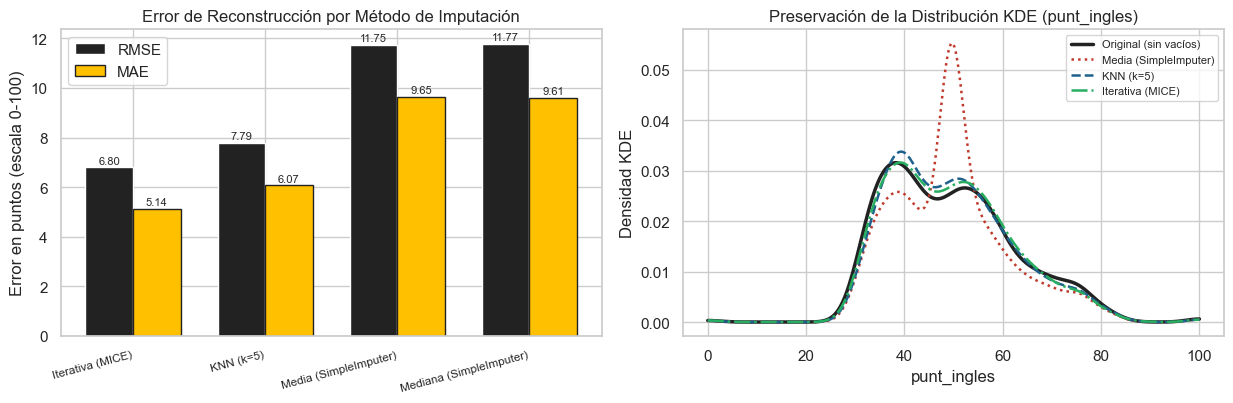

In [5]:
res_imputacion = E.comparar_imputacion_numerica(df, porcentaje=0.20, n_muestra=3000, semilla=42)
print("Comparación de métodos de imputación numérica (20 % de datos ocultos, n = 3.000):")
display(res_imputacion["resultados"])

fig = G.fig_imputacion_comparativa(res_imputacion, col="punt_ingles")
fig.savefig(RUTA_FIG / "01_imputacion_comparativa.png", dpi=150, bbox_inches="tight")
plt.show()

**Lectura del experimento de imputación:**
- **MICE (`IterativeImputer`)** y **KNN ($k=5$)** logran los menores errores de reconstrucción (RMSE de **7,2706** y **7,8922** puntos frente a **11,9320** de la media simple) y preservan fielmente la forma de la distribución original en la curva KDE.
- La imputación por tendencia central (**Media / Mediana**) concentra todos los valores faltantes en un único punto, generando un pico artificial en el centro de la densidad KDE y subestimando la varianza si la proporción de vacíos es alta (como el $20\%$ simulado). No obstante, dentro del `Pipeline` supervisado donde los predictores no contienen a las demás pruebas de área (para evitar *data leakage*) y `punt_ingles` solo presenta un **$0{,}36\%$** de faltantes ($282$ de $77.827$), `SimpleImputer(strategy='median')` dentro del `num_pipeline` resulta computacionalmente rápido, robusto a la asimetría derecha de inglés y libre de fuga de información.

---
## 4. Análisis Exploratorio de Datos (EDA)

### 4.1 Exploración Univariada: Medidas Estructurales, Posición, Forma y Atípicos (IQR)
Se calculan las medidas de tendencia central (media, mediana, moda), dispersión (rango, varianza muestral $s^2$, desviación estándar $s$, coeficiente de variación $\text{CV}$), posición ($Q_1, Q_2, Q_3, P_{10}, P_{90}, \text{IQR}$), forma (asimetría de Fisher-Pearson $g_1$ y exceso de curtosis $g_2$) y detección de valores atípicos mediante el criterio $[Q_1 - 1{,}5\cdot\text{IQR},\; Q_3 + 1{,}5\cdot\text{IQR}]$.

In [6]:
desc = E.descriptivas(df, datos.COLS_CUANT)

print("1. Medidas de Tendencia Central:")
display(desc[["n", "media", "mediana", "moda", "n_modas"]].T)

print("\n2. Medidas de Dispersión:")
display(desc[["minimo", "maximo", "rango", "varianza", "desv_estandar", "coef_variacion_%"]].T)

print("\n3. Medidas de Posición:")
display(desc[["Q1", "Q2", "Q3", "P10", "P90", "IQR"]].T)

print("\n4. Medidas de Forma y Conteo de Atípicos (1,5·IQR):")
display(desc[["asimetria", "curtosis", "exceso_curtosis", "forma_asimetria", "forma_curtosis", "lim_inf_IQR", "lim_sup_IQR", "n_atipicos", "%_atipicos"]])

md_("### Interpretación de Medidas Estructurales y de Forma\n" + E.interpretar_univariada(desc) + "\n\n" + E.interpretar_forma(desc))

1. Medidas de Tendencia Central:


variable,punt_global,punt_matematicas,punt_lectura_critica,punt_c_naturales,punt_sociales_ciudadanas,punt_ingles
n,"77,827.0000","77,827.0000","77,827.0000","77,827.0000","77,827.0000","77,545.0000"
media,249.9140,50.5266,52.7652,49.0519,47.6498,49.8273
mediana,247.0000,51.0000,53.0000,48.0000,47.0000,49.0000
moda,240.0000,53.0000,53.0000,43.0000,40.0000,39.0000
n_modas,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000



2. Medidas de Dispersión:


variable,punt_global,punt_matematicas,punt_lectura_critica,punt_c_naturales,punt_sociales_ciudadanas,punt_ingles
minimo,12.0000,0.0000,0.0000,0.0000,0.0000,0.0000
maximo,477.0000,100.0000,100.0000,100.0000,100.0000,100.0000
rango,465.0000,100.0000,100.0000,100.0000,100.0000,100.0000
varianza,"2,675.4579",149.3213,115.5771,107.5530,141.5951,171.0961
desv_estandar,51.7248,12.2197,10.7507,10.3708,11.8994,13.0804
coef_variacion_%,20.6971,24.1847,20.3746,21.1424,24.9726,26.2514



3. Medidas de Posición:


variable,punt_global,punt_matematicas,punt_lectura_critica,punt_c_naturales,punt_sociales_ciudadanas,punt_ingles
Q1,210.0000,42.0000,45.0000,41.0000,38.0000,39.0000
Q2,247.0000,51.0000,53.0000,48.0000,47.0000,49.0000
Q3,287.0000,59.0000,61.0000,56.0000,57.0000,58.0000
P10,183.0000,34.0000,38.0000,36.0000,32.0000,34.0000
P90,321.0000,66.0000,67.0000,63.0000,64.0000,68.0000
IQR,77.0000,17.0000,16.0000,15.0000,19.0000,19.0000



4. Medidas de Forma y Conteo de Atípicos (1,5·IQR):


,asimetria,curtosis,exceso_curtosis,forma_asimetria,forma_curtosis,lim_inf_IQR,lim_sup_IQR,n_atipicos,%_atipicos
variable,,,,,,,,,
punt_global,0.2776,2.4825,-0.5175,Aproximadamente simétrica,Platicúrtica,94.5000,402.5000,131,0.1683
punt_matematicas,0.0430,2.8752,-0.1248,Aproximadamente simétrica,Mesocúrtica,16.5000,84.5000,156,0.2004
punt_lectura_critica,0.0164,2.7233,-0.2767,Aproximadamente simétrica,Mesocúrtica,21.0000,85.0000,79,0.1015
punt_c_naturales,0.3388,2.5857,-0.4143,Aproximadamente simétrica,Mesocúrtica,18.5000,78.5000,129,0.1658
punt_sociales_ciudadanas,0.2060,2.3543,-0.6457,Aproximadamente simétrica,Platicúrtica,9.5000,85.5000,10,0.0128
punt_ingles,0.5769,3.4869,0.4869,Asimétrica moderada positiva (cola derecha),Mesocúrtica,10.5000,86.5000,517,0.6667


### Interpretación de Medidas Estructurales y de Forma
- **`punt_global`**: media = 249.9140, mediana = 247.0000 y moda = 240.0000; la media supera a la mediana (sesgo positivo hacia valores altos). Desviación estándar = 51.7248 (CV = 20.6971 %). El 50 % central se ubica entre Q1 = 210.0000 y Q3 = 287.0000 (IQR = 77.0000); el 10 % inferior obtiene menos de 183.0000 y el 10 % superior supera 321.0000.
- **`punt_matematicas`**: media = 50.5266, mediana = 51.0000 y moda = 53.0000; la media es menor que la mediana (sesgo negativo hacia valores bajos). Desviación estándar = 12.2197 (CV = 24.1847 %). El 50 % central se ubica entre Q1 = 42.0000 y Q3 = 59.0000 (IQR = 17.0000); el 10 % inferior obtiene menos de 34.0000 y el 10 % superior supera 66.0000.
- **`punt_lectura_critica`**: media = 52.7652, mediana = 53.0000 y moda = 53.0000; la media es menor que la mediana (sesgo negativo hacia valores bajos). Desviación estándar = 10.7507 (CV = 20.3746 %). El 50 % central se ubica entre Q1 = 45.0000 y Q3 = 61.0000 (IQR = 16.0000); el 10 % inferior obtiene menos de 38.0000 y el 10 % superior supera 67.0000.
- **`punt_c_naturales`**: media = 49.0519, mediana = 48.0000 y moda = 43.0000; la media supera a la mediana (sesgo positivo hacia valores altos). Desviación estándar = 10.3708 (CV = 21.1424 %). El 50 % central se ubica entre Q1 = 41.0000 y Q3 = 56.0000 (IQR = 15.0000); el 10 % inferior obtiene menos de 36.0000 y el 10 % superior supera 63.0000.
- **`punt_sociales_ciudadanas`**: media = 47.6498, mediana = 47.0000 y moda = 40.0000; la media supera a la mediana (sesgo positivo hacia valores altos). Desviación estándar = 11.8994 (CV = 24.9726 %). El 50 % central se ubica entre Q1 = 38.0000 y Q3 = 57.0000 (IQR = 19.0000); el 10 % inferior obtiene menos de 32.0000 y el 10 % superior supera 64.0000.
- **`punt_ingles`**: media = 49.8273, mediana = 49.0000 y moda = 39.0000; la media supera a la mediana (sesgo positivo hacia valores altos). Desviación estándar = 13.0804 (CV = 26.2514 %). El 50 % central se ubica entre Q1 = 39.0000 y Q3 = 58.0000 (IQR = 19.0000); el 10 % inferior obtiene menos de 34.0000 y el 10 % superior supera 68.0000.

**Comparación de variabilidad relativa (CV):** dado que `punt_global` (0–500) y las pruebas por área (0–100) tienen escalas distintas, se comparan mediante el Coeficiente de Variación. La mayor dispersión relativa se presenta en **`punt_ingles`** (26.2514 %) y la menor en **`punt_lectura_critica`** (20.3746 %).

- **`punt_global`**: asimetría $g_1$ = 0.2776 → aproximadamente simétrica; curtosis = 2.4825 (exceso = -0.5175) → platicúrtica; atípicos IQR = 131 (0.1683 %).
- **`punt_matematicas`**: asimetría $g_1$ = 0.0430 → aproximadamente simétrica; curtosis = 2.8752 (exceso = -0.1248) → mesocúrtica; atípicos IQR = 156 (0.2004 %).
- **`punt_lectura_critica`**: asimetría $g_1$ = 0.0164 → aproximadamente simétrica; curtosis = 2.7233 (exceso = -0.2767) → mesocúrtica; atípicos IQR = 79 (0.1015 %).
- **`punt_c_naturales`**: asimetría $g_1$ = 0.3388 → aproximadamente simétrica; curtosis = 2.5857 (exceso = -0.4143) → mesocúrtica; atípicos IQR = 129 (0.1658 %).
- **`punt_sociales_ciudadanas`**: asimetría $g_1$ = 0.2060 → aproximadamente simétrica; curtosis = 2.3543 (exceso = -0.6457) → platicúrtica; atípicos IQR = 10 (0.0128 %).
- **`punt_ingles`**: asimetría $g_1$ = 0.5769 → asimétrica moderada positiva (cola derecha); curtosis = 3.4869 (exceso = 0.4869) → mesocúrtica; atípicos IQR = 517 (0.6667 %).

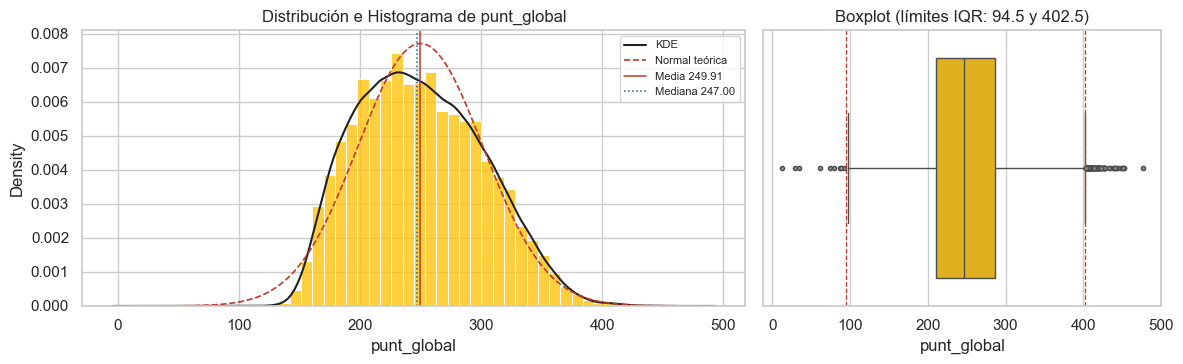

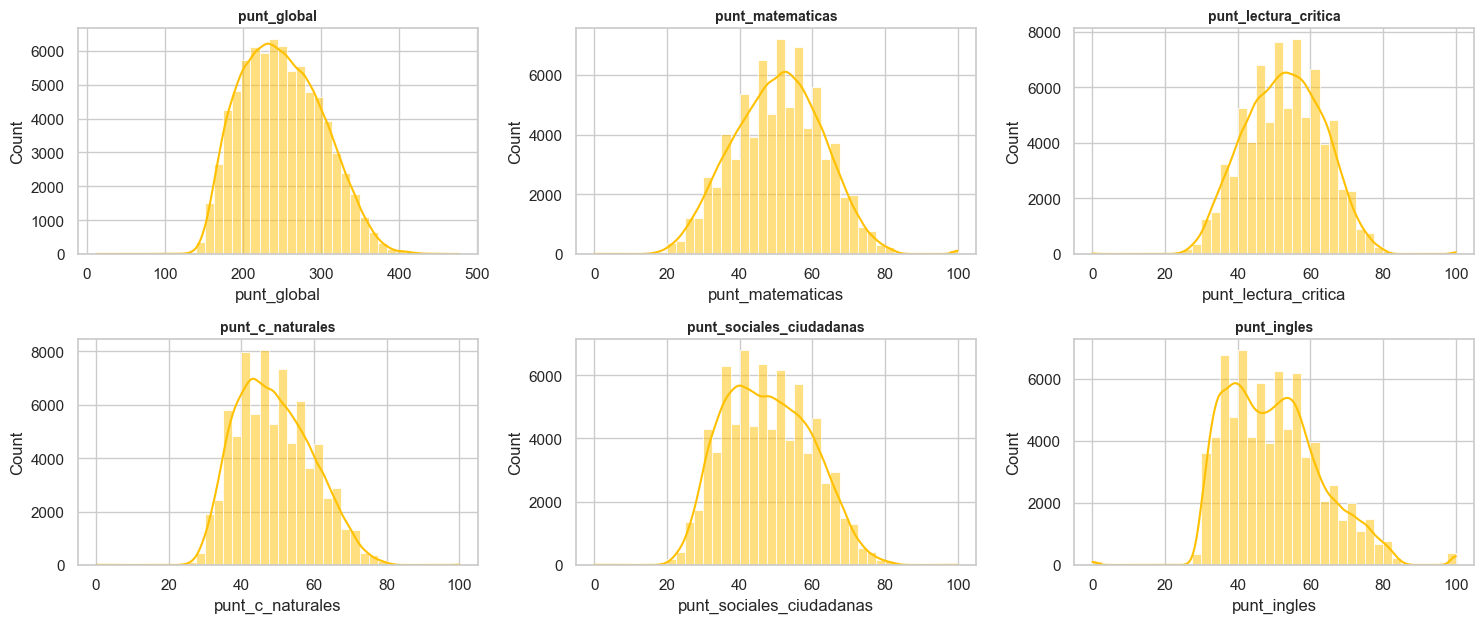

con_atipicos                                                 sin_atipicos                                                 diferencia                                        \
medida                      asimetria desv_estandar exceso_curtosis    media  mediana    asimetria desv_estandar exceso_curtosis    media  mediana  asimetria desv_estandar exceso_curtosis   media   
variable                                                                                                                                                                                              
punt_c_naturales               0.3388       10.3708         -0.4143  49.0519  48.0000       0.3122       10.2846         -0.5703  49.0037  48.0000    -0.0265       -0.0862         -0.1560 -0.0482   
punt_global                    0.2776       51.7248         -0.5175 249.9140 247.0000       0.2507       51.3046         -0.6295 249.6749 247.0000    -0.0269       -0.4203         -0.1120 -0.2390   
punt_ingles                    0.5769       13.0804          0.4869  49.8273  49.0000       0.4985       12.4653         -0.4681  49.6658  49.0000    -0.0784       -0.6151         -0.9551 -0.1615   
punt_lectura_critica           0.0164       10.7507         -0.2767  52.7652  53.0000      -0.0234       10.6452         -0.6002  52.7365  53.0000    -0.0398       -0.1055         -0.3234 -0.0287   
punt_matematicas               0.0430       12.2197         -0.1248  50.5266  51.0000      -0.0513       12.0374         -0.4805  50.4465  51.0000    -0.0943       -0.1823         -0.3558 -0.0801   
punt_sociales_ciudadanas       0.2060       11.8994         -0.6457  47.6498  47.0000       0.2054       11.8866         -0.6760  47.6495  47.0000    -0.0006       -0.0128         -0.0303 -0.0003   

                                  
medida                   mediana  
variable                          
punt_c_naturales          0.0000  
punt_global               0.0000  
punt_ingles               0.0000  
punt_lectura_critica      0.0000  
punt_matematicas          0.0000  
punt_sociales_ciudadanas  0.0000

### Impacto de los Valores Atípicos (Criterio IQR)
- **`punt_global`**: 131 atípicos detectados. Al filtrarlos, la media varía -0.2390 puntos, la mediana 0.0000 y la desviación estándar -0.4203. Como corresponden a desempeños reales dentro del rango oficial del ICFES ([0, 100] o [0, 500]), **se conservan en el modelado**.
- **`punt_matematicas`**: 156 atípicos detectados. Al filtrarlos, la media varía -0.0801 puntos, la mediana 0.0000 y la desviación estándar -0.1823. Como corresponden a desempeños reales dentro del rango oficial del ICFES ([0, 100] o [0, 500]), **se conservan en el modelado**.
- **`punt_lectura_critica`**: 79 atípicos detectados. Al filtrarlos, la media varía -0.0287 puntos, la mediana 0.0000 y la desviación estándar -0.1055. Como corresponden a desempeños reales dentro del rango oficial del ICFES ([0, 100] o [0, 500]), **se conservan en el modelado**.
- **`punt_c_naturales`**: 129 atípicos detectados. Al filtrarlos, la media varía -0.0482 puntos, la mediana 0.0000 y la desviación estándar -0.0862. Como corresponden a desempeños reales dentro del rango oficial del ICFES ([0, 100] o [0, 500]), **se conservan en el modelado**.
- **`punt_sociales_ciudadanas`**: 10 atípicos detectados. Al filtrarlos, la media varía -0.0003 puntos, la mediana 0.0000 y la desviación estándar -0.0128. Como corresponden a desempeños reales dentro del rango oficial del ICFES ([0, 100] o [0, 500]), **se conservan en el modelado**.
- **`punt_ingles`**: 517 atípicos detectados. Al filtrarlos, la media varía -0.1615 puntos, la mediana 0.0000 y la desviación estándar -0.6151. Como corresponden a desempeños reales dentro del rango oficial del ICFES ([0, 100] o [0, 500]), **se conservan en el modelado**.

In [7]:
# Visualización detallada de la variable objetivo (punt_global) y grilla de variables cuantitativas
fig = G.hist_box(df, "punt_global")
fig.savefig(RUTA_FIG / "02_hist_box_punt_global.png", dpi=150, bbox_inches="tight")
plt.show()

fig = G.grilla_hist(df, datos.COLS_CUANT)
fig.savefig(RUTA_FIG / "03_grilla_histogramas.png", dpi=150, bbox_inches="tight")
plt.show()

# Evaluación del impacto de los valores atípicos sobre los estimadores descriptivos
imp_out = E.impacto_outliers(df, datos.COLS_CUANT)
display(imp_out.pivot(index="variable", columns="medida", values=["con_atipicos", "sin_atipicos", "diferencia"]))
md_("### Impacto de los Valores Atípicos (Criterio IQR)\n" + E.interpretar_outliers(imp_out))

### 4.2 Análisis Univariado y Bivariado de Variables Cualitativas (Contexto Socioeconómico)
Se examina la distribución porcentual de las seis variables cualitativas predictoras y su relación visual con el puntaje global mediante diagramas de caja y bigotes (*boxplots*):

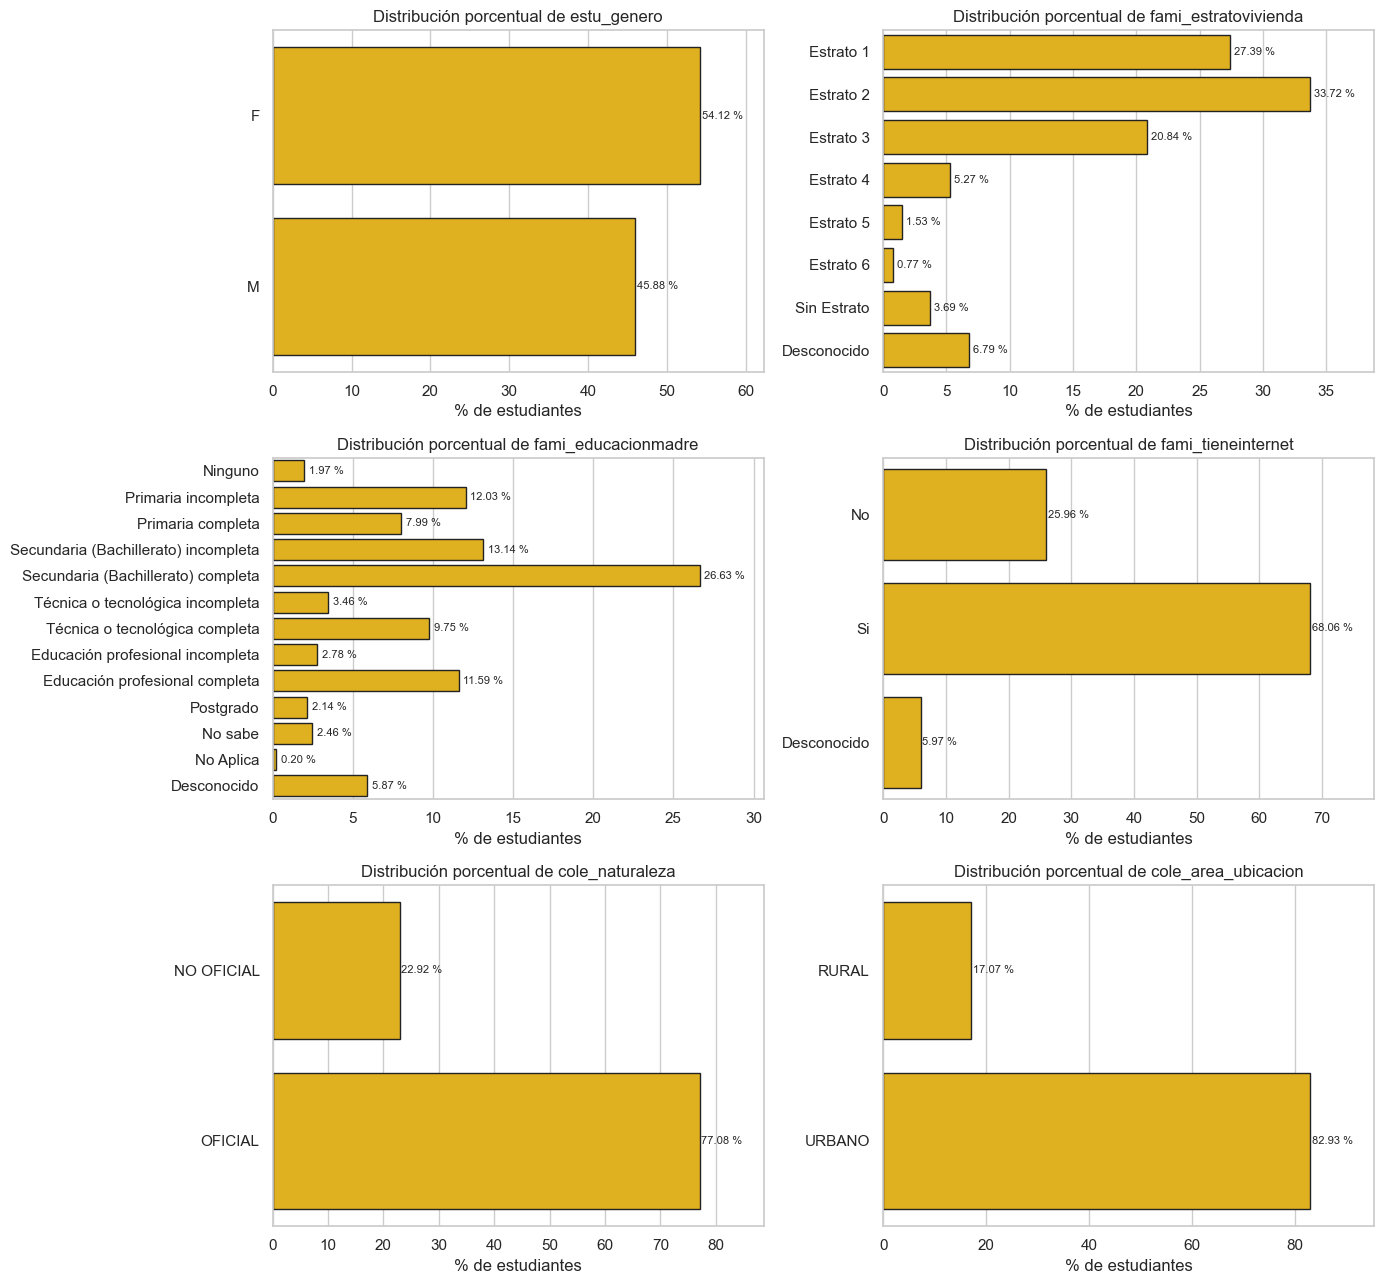

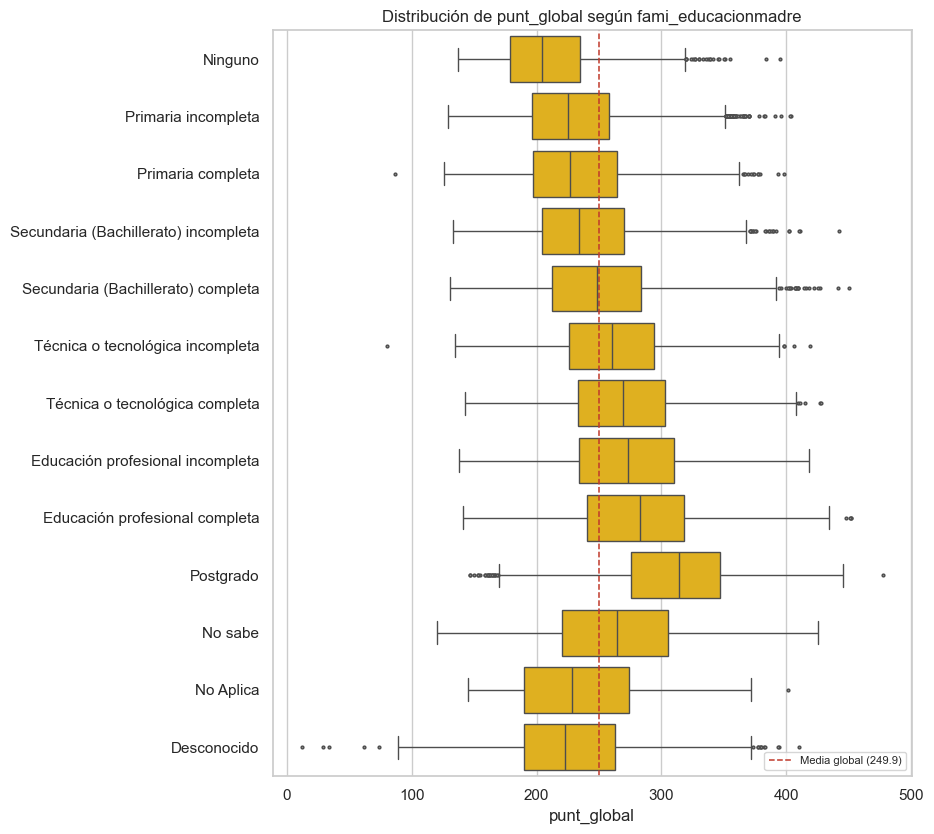

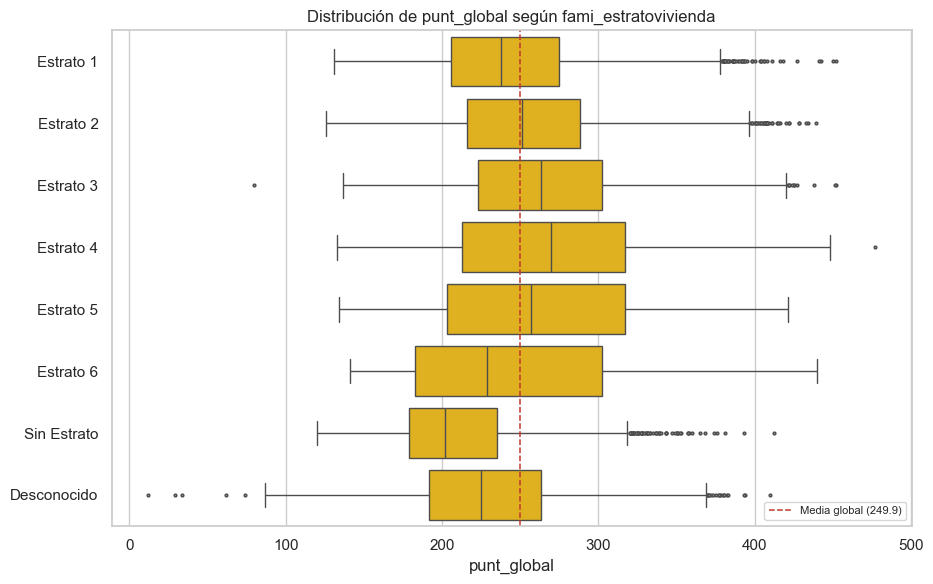

In [8]:
fig, axs = plt.subplots(3, 2, figsize=(14, 13))
for ax, col in zip(np.ravel(axs), datos.COLS_CUAL):
    G.barras(df, col, ax=ax)
fig.tight_layout()
fig.savefig(RUTA_FIG / "04_barras_cualitativas.png", dpi=150, bbox_inches="tight")
plt.show()

# Boxplots de punt_global según los dos predictores de mayor impacto: educación de la madre y estrato
for col_cat in ["fami_educacionmadre", "fami_estratovivienda"]:
    fig = G.boxplot_grupos(df, col_cat, "punt_global")
    fig.savefig(RUTA_FIG / f"05_boxplot_{col_cat}.png", dpi=150, bbox_inches="tight")
    plt.show()

---
## 5. Pruebas de Hipótesis e Interpretación

En concordancia con el **Laboratorio 2**, antes de entrenar los modelos predictivos se validan formalmente las hipótesis estadísticas de asociación para tres tipos de relaciones:
1. **Variables Continuas vs Continuas:** Covarianza, correlación lineal paramétrica de **Pearson ($r$)** y correlaciones por rangos no paramétricas de **Spearman ($\rho$)** y **Kendall ($\tau$)**, incluyendo el experimento de sensibilidad frente a valores atípicos.
2. **Variables Categóricas vs Categóricas:** Prueba de independencia **Chi-cuadrado ($\chi^2$)**, **$V$ de Cramér** corregida por sesgo, **Información Mutua (MI)** normalizada y análisis de residuos estandarizados ajustados.
3. **Variables Mixtas (Cualitativa vs Cuantitativa Continua):** Evaluación de normalidad intragrupo (Shapiro-Wilk y D'Agostino-Pearson), prueba de homocedasticidad de **Levene (Brown-Forsythe)** y **Bartlett**, contraste paramétrico **ANOVA de un factor ($F$, $\eta^2$)**, **ANOVA de Welch ($F_W$, $\omega^2$)** y contraste no paramétrico de **Kruskal-Wallis ($H$, $\varepsilon^2$)**.

,n,covarianza,pearson,p_pearson,spearman,p_spearman,kendall,p_kendall,pearson_sin_atipicos,spearman_sin_atipicos,n_excluidos_atipicos,R2_lineal,R2_cuadratico
par,,,,,,,,,,,,,
punt_matematicas vs punt_global,77827,573.7823,0.9078,< 0.0001,0.9087,< 0.0001,0.7479,< 0.0001,0.9065,0.9080,200,0.8241,0.8282
punt_lectura_critica vs punt_global,77827,506.2926,0.9105,< 0.0001,0.9137,< 0.0001,0.7535,< 0.0001,0.9103,0.9132,169,0.8290,0.8329
punt_ingles vs punt_global,77545,541.2595,0.8006,< 0.0001,0.7905,< 0.0001,0.6010,< 0.0001,0.7987,0.7864,604,0.6409,0.6409
punt_ingles vs punt_matematicas,77545,107.6137,0.6739,< 0.0001,0.6750,< 0.0001,0.4963,< 0.0001,0.6704,0.6690,650,0.4542,0.4542


- **`punt_matematicas` vs `punt_global`** ($n = 77,827$): asociación muy fuerte positiva (Pearson $r = 0.9078$, $p$ < 0.0001; covarianza = 573.7823). Spearman $\rho = 0.9087$ ($p$ < 0.0001) y Kendall $\tau = 0.7479$ ($p$ < 0.0001). Pearson y Spearman casi coinciden: la dependencia es esencialmente lineal y sin distorsión por extremos. Sin los 200 atípicos IQR, Pearson pasa a 0.9065 (cambio = -0.0013), y el ajuste cuadrático aporta $\Delta R^2 = 0.0041$ (0.8241 → 0.8282).

- **`punt_lectura_critica` vs `punt_global`** ($n = 77,827$): asociación muy fuerte positiva (Pearson $r = 0.9105$, $p$ < 0.0001; covarianza = 506.2926). Spearman $\rho = 0.9137$ ($p$ < 0.0001) y Kendall $\tau = 0.7535$ ($p$ < 0.0001). Pearson y Spearman casi coinciden: la dependencia es esencialmente lineal y sin distorsión por extremos. Sin los 169 atípicos IQR, Pearson pasa a 0.9103 (cambio = -0.0002), y el ajuste cuadrático aporta $\Delta R^2 = 0.0040$ (0.8290 → 0.8329).

- **`punt_ingles` vs `punt_global`** ($n = 77,545$): asociación muy fuerte positiva (Pearson $r = 0.8006$, $p$ < 0.0001; covarianza = 541.2595). Spearman $\rho = 0.7905$ ($p$ < 0.0001) y Kendall $\tau = 0.6010$ ($p$ < 0.0001). Pearson y Spearman casi coinciden: la dependencia es esencialmente lineal y sin distorsión por extremos. Sin los 604 atípicos IQR, Pearson pasa a 0.7987 (cambio = -0.0019), y el ajuste cuadrático aporta $\Delta R^2 = 0.0000$ (0.6409 → 0.6409).

- **`punt_ingles` vs `punt_matematicas`** ($n = 77,545$): asociación fuerte positiva (Pearson $r = 0.6739$, $p$ < 0.0001; covarianza = 107.6137). Spearman $\rho = 0.6750$ ($p$ < 0.0001) y Kendall $\tau = 0.4963$ ($p$ < 0.0001). Pearson y Spearman casi coinciden: la dependencia es esencialmente lineal y sin distorsión por extremos. Sin los 650 atípicos IQR, Pearson pasa a 0.6704 (cambio = -0.0035), y el ajuste cuadrático aporta $\Delta R^2 = 0.0001$ (0.4542 → 0.4542).

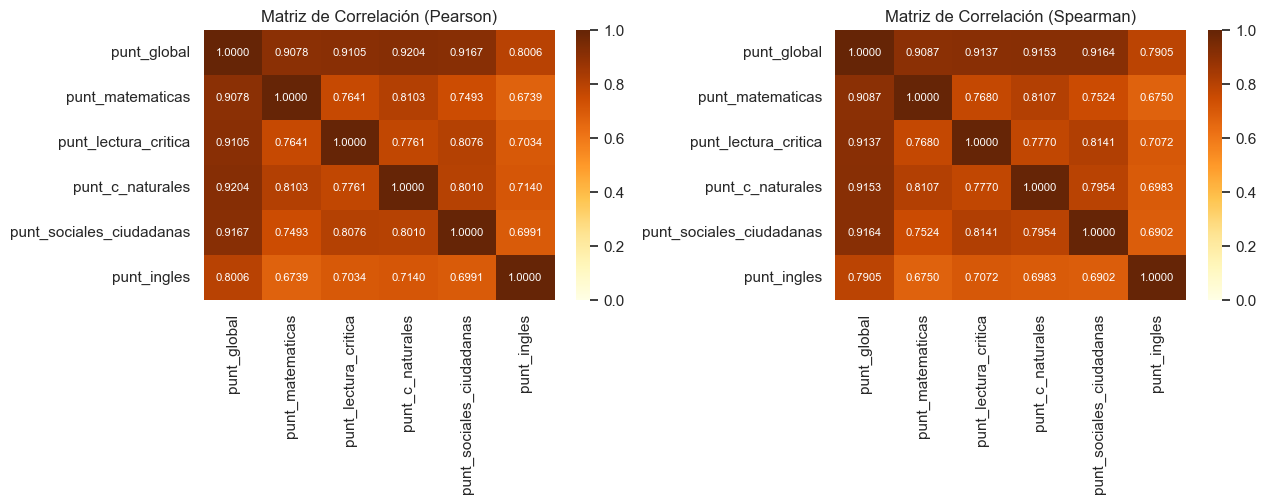

In [9]:
# 5.1 Asociación entre variables continuas (Pearson, Spearman y Kendall)
pares_cont = [
    ("punt_matematicas", "punt_global"),
    ("punt_lectura_critica", "punt_global"),
    ("punt_ingles", "punt_global"),
    ("punt_ingles", "punt_matematicas"),
]
tabla_corr = E.tabla_correlaciones(df, pares_cont)
display(E.formatear_pvalores(tabla_corr))

for x_c, y_c in pares_cont:
    md_("- " + E.interpretar_correlacion(E.correlacion_par(df, x_c, y_c)))

fig, axs = plt.subplots(1, 2, figsize=(13, 5.2))
G.heatmap_corr(df, datos.COLS_CUANT, "pearson", ax=axs[0])
G.heatmap_corr(df, datos.COLS_CUANT, "spearman", ax=axs[1])
fig.tight_layout()
fig.savefig(RUTA_FIG / "06_heatmaps_correlacion.png", dpi=150, bbox_inches="tight")
plt.show()

,n,chi2,gl,p_chi2,V_Cramer,V_Cramer_corregido,MI_nats,MI_normalizada,G=2n·MI,p_MI_perm,%_esperadas<5
par,,,,,,,,,,,
fami_estratovivienda × fami_educacionmadre,77827,"72,468.9060",84,< 0.0001,0.3647,0.3645,0.2374,0.1476,"36,952.8464",0.0050,1.9231
cole_naturaleza × fami_tieneinternet,77827,"3,180.5676",2,< 0.0001,0.2022,0.2021,0.0234,0.0434,"3,635.8045",0.0050,0.0000
estu_genero × cole_area_ubicacion,77827,0.0640,1,0.8003,0.0009,0.0000,0.0000,0.0000,0.0689,0.8060,0.0000


- **`fami_estratovivienda` × `fami_educacionmadre`**: $\chi^2 = 72,468.9060$ (84 gl), $p$ < 0.0001 → se rechaza $H_0$ (existe dependencia estadísticamente significativa). Magnitud **moderada** ($V$ de Cramér = 0.3647, corregida = 0.3645; MI = 0.2374 nats, MI normalizada = 0.1476). Esto indica colinealidad moderada entre predictores socioeconómicos que el modelo lineal controla mediante efectos parciales.

- **`cole_naturaleza` × `fami_tieneinternet`**: $\chi^2 = 3,180.5676$ (2 gl), $p$ < 0.0001 → se rechaza $H_0$ (existe dependencia estadísticamente significativa). Magnitud **débil** ($V$ de Cramér = 0.2022, corregida = 0.2021; MI = 0.0234 nats, MI normalizada = 0.0434). Esto indica colinealidad moderada entre predictores socioeconómicos que el modelo lineal controla mediante efectos parciales.

- **`estu_genero` × `cole_area_ubicacion`**: $\chi^2 = 0.0640$ (1 gl), $p$ 0.8003 → no se rechaza $H_0$. Magnitud **despreciable** ($V$ de Cramér = 0.0009, corregida = 0.0000; MI = 0.0000 nats, MI normalizada = 0.0000). 

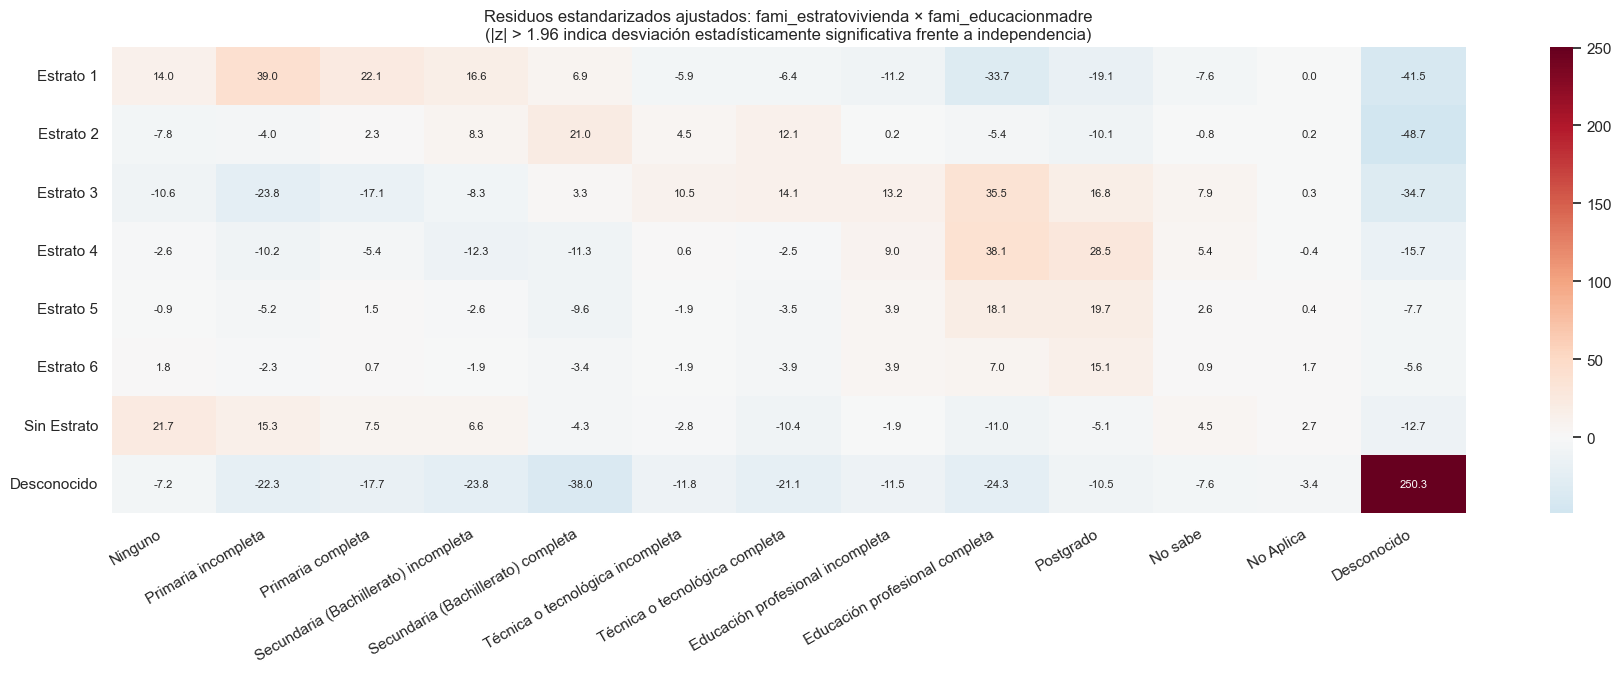

In [10]:
# 5.2 Pruebas de independencia para variables categóricas (Chi-cuadrado e Información Mutua)
pares_cat = [
    ("fami_estratovivienda", "fami_educacionmadre"),
    ("cole_naturaleza", "fami_tieneinternet"),
    ("estu_genero", "cole_area_ubicacion"),
]
res_cat = [E.independencia_categoricas(df, a, b, n_perm=200) for a, b in pares_cat]
display(E.formatear_pvalores(E.resumen_independencia(res_cat)))

for r in res_cat:
    md_(E.interpretar_independencia(r))

fig = G.heatmap_residuos(res_cat[0])
fig.savefig(RUTA_FIG / "07_residuos_chi2_estrato_educacion.png", dpi=150, bbox_inches="tight")
plt.show()

### Contraste de Hipótesis Mixto: `fami_educacionmadre` → `punt_global`

,estadistico,gl,p_valor,tamaño_efecto
prueba,,,,
Levene (Brown-Forsythe),72.6329,"12, 77814",< 0.0001,NaN
Bartlett,769.2265,12,< 0.0001,NaN
ANOVA de un factor,"1,020.3916","12, 77814",< 0.0001,0.1360
ANOVA de Welch,975.1515,"12, 5,814.05",< 0.0001,0.1358
Kruskal-Wallis,"9,932.8757",12,< 0.0001,0.1275


**`fami_educacionmadre` → `punt_global`** ($k = 13$ grupos, $N = 77,827$):
- **Supuesto de normalidad intragrupo:** D'Agostino-Pearson rechaza $H_0$ en el 100.0 % de los grupos (esperado con tamaños muestrales grandes), aunque la asimetría se mantiene acotada en $[-0.4944, 0.8260]$.
- **Supuesto de homocedasticidad:** Levene $W = 72.6329$ ($p$ < 0.0001) → se rechaza igualdad de varianzas (heterocedasticidad entre grupos); razón $\sigma_{\max}/\sigma_{\min} = 1.3629$.
- **Contraste de medias y medianas:** ANOVA clásico $F = 1,020.3916$ ($p$ < 0.0001, $\eta^2 = 0.1360$), ANOVA de Welch $F_W = 975.1515$ ($p$ < 0.0001, $\omega^2 = 0.1358$) y Kruskal-Wallis $H = 9,932.8757$ ($p$ < 0.0001, $\varepsilon^2 = 0.1275$).
- **Decisión estadística:** al violarse la homocedasticidad con tamaños de grupo desbalanceados, las pruebas rigurosas de referencia son **Kruskal-Wallis** (no paramétrica) y **ANOVA de Welch** (robusta a varianzas desiguales). Ambas confirman que `fami_educacionmadre` explica el **13.60 %** de la variabilidad de `punt_global`.

### Contraste de Hipótesis Mixto: `fami_estratovivienda` → `punt_global`

,estadistico,gl,p_valor,tamaño_efecto
prueba,,,,
Levene (Brown-Forsythe),279.5300,"7, 77819",< 0.0001,NaN
Bartlett,"1,256.4902",7,< 0.0001,NaN
ANOVA de un factor,685.7359,"7, 77819",< 0.0001,0.0581
ANOVA de Welch,740.0002,"7, 6,400.08",< 0.0001,0.0580
Kruskal-Wallis,"4,416.1447",7,< 0.0001,0.0567


**`fami_estratovivienda` → `punt_global`** ($k = 8$ grupos, $N = 77,827$):
- **Supuesto de normalidad intragrupo:** D'Agostino-Pearson rechaza $H_0$ en el 100.0 % de los grupos (esperado con tamaños muestrales grandes), aunque la asimetría se mantiene acotada en $[0.0118, 0.9588]$.
- **Supuesto de homocedasticidad:** Levene $W = 279.5300$ ($p$ < 0.0001) → se rechaza igualdad de varianzas (heterocedasticidad entre grupos); razón $\sigma_{\max}/\sigma_{\min} = 1.6461$.
- **Contraste de medias y medianas:** ANOVA clásico $F = 685.7359$ ($p$ < 0.0001, $\eta^2 = 0.0581$), ANOVA de Welch $F_W = 740.0002$ ($p$ < 0.0001, $\omega^2 = 0.0580$) y Kruskal-Wallis $H = 4,416.1447$ ($p$ < 0.0001, $\varepsilon^2 = 0.0567$).
- **Decisión estadística:** al violarse la homocedasticidad con tamaños de grupo desbalanceados, las pruebas rigurosas de referencia son **Kruskal-Wallis** (no paramétrica) y **ANOVA de Welch** (robusta a varianzas desiguales). Ambas confirman que `fami_estratovivienda` explica el **5.81 %** de la variabilidad de `punt_global`.

Síntesis de fuerza de asociación de los predictores con punt_global:


,k_grupos,F_anova,F_welch,H_kruskal,p_kruskal,epsilon2,eta2,MI_normalizada,dif_medianas
variable,,,,,,,,,
fami_educacionmadre,13,"1,020.3916",975.1515,"9,932.8757",< 0.0001,0.1275,0.1360,0.0334,110.0000
fami_tieneinternet,3,"3,321.6655","3,652.6609","6,187.7575",< 0.0001,0.0795,0.0786,0.0536,36.0000
fami_estratovivienda,8,685.7359,740.0002,"4,416.1447",< 0.0001,0.0567,0.0581,0.0239,68.0000
cole_naturaleza,2,"4,488.8758","3,792.5135","3,662.2795",< 0.0001,0.0470,0.0545,0.0534,35.0000
cole_area_ubicacion,2,"2,792.5612","3,079.1699","2,779.9036",< 0.0001,0.0357,0.0346,0.0396,30.0000
estu_genero,2,465.8346,462.0961,436.5788,< 0.0001,0.0056,0.0060,0.0047,10.0000


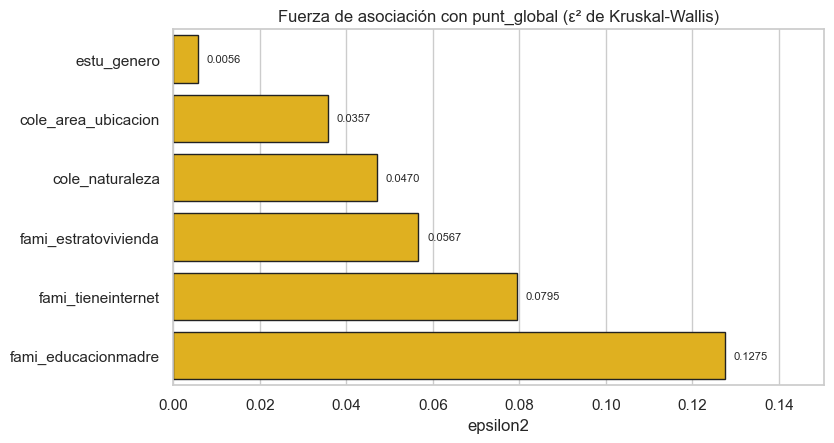

In [11]:
# 5.3 Asociación entre variables mixtas: Supuestos, ANOVA, Welch y Kruskal-Wallis
for cat_m in ["fami_educacionmadre", "fami_estratovivienda"]:
    res_m = E.analisis_mixto(df, cat_m, "punt_global")
    md_(f"### Contraste de Hipótesis Mixto: `{cat_m}` → `punt_global`")
    display(E.formatear_pvalores(E.tabla_pruebas_mixtas(res_m)))
    md_(E.interpretar_mixto(res_m))

# Ranking global de asociación de todos los predictores cualitativos con punt_global
rank_cat = E.ranking_asociacion(df, "punt_global")
print("Síntesis de fuerza de asociación de los predictores con punt_global:")
display(E.formatear_pvalores(rank_cat))

fig = G.barras_ranking(rank_cat, "epsilon2", "Fuerza de asociación con punt_global (ε² de Kruskal-Wallis)")
fig.savefig(RUTA_FIG / "08_ranking_predictores_epsilon2.png", dpi=150, bbox_inches="tight")
plt.show()

---
## 6. Construcción de Pipelines y Escalamiento

### 6.1 Fundamento Metodológico del `Pipeline` y `ColumnTransformer` (Notebook 7)
Un **Pipeline** encadena secuencialmente las etapas de transformación de datos (imputación, codificación y escalamiento) y el estimador predictivo en un único objeto reproducible:
- **Prevención estricta de *data leakage*:** Durante el ajuste (`fit`) sobre `X_train` y en cada iteración de la validación cruzada (`cross_validate`), los parámetros de imputación (mediana) y estandarización (media $\mu$ y desviación estándar $\sigma$) se calculan **exclusivamente sobre el subconjunto de entrenamiento** y luego se aplican mediante `transform` sobre el pliegue de validación o prueba (`X_test`).
- **Codificación *Dummy* ($k-1$, `drop='first'`) vs *One-Hot* ($k$):** Para modelos lineales (`LinearRegression` y `LogisticRegression`), crear $k$ columnas binarias por cada variable categórica genera colinealidad exacta con el intercepto ($\sum_{j=1}^k O_j = 1$, conocida como la **trampa de las variables dummy**). Por ello se configura `OneHotEncoder(categories=..., drop='first', handle_unknown='ignore')`, fijando categorías base de referencia claras (`No` en internet, `NO OFICIAL` en naturaleza, `RURAL` en zona, `F` en género y `No` en indicadores de categoría especial).
- **Estandarización (`StandardScaler`) vs Normalización (`MinMaxScaler`):**
  $$z = \frac{x - \mu}{\sigma} \quad (\text{StandardScaler: media } 0,\; \sigma = 1) \qquad\qquad w = \frac{x - x_{\min}}{x_{\max} - x_{\min}} \quad (\text{MinMaxScaler: rango } [0, 1])$$
  Se elige `StandardScaler()` porque es menos sensible a valores extremos que `MinMaxScaler`, acelera la convergencia de los *solvers* iterativos (`liblinear`) en Regresión Logística con penalización $L_1/L_2$, y permite interpretar directamente los coeficientes de las variables numéricas en términos de desviaciones estándar.

In [12]:
# 6.2 Demostración matemática del impacto del escalamiento sobre distancias (Notebook 7)
dem_esc = E.demostracion_escalamiento_distancias(df)
print("Perfiles de estudiantes en escalas diferentes (educ_madre_nivel [0–9] vs punt_ingles [0–100]):")
display(dem_esc["perfiles"])

print("\nComparación de Distancias Euclidianas d(Pi, Pj) sin escalar vs StandardScaler vs MinMaxScaler:")
display(dem_esc["distancias"])

md_("""**Conclusión de la demostración de escalamiento:**
- **Sin escalar**, la diferencia de $15$ puntos en inglés entre el Estudiante A y el Estudiante B ($d(P_1, P_2) = 15{,}0333$) parece casi **dos veces mayor** que la diferencia entre el Estudiante A (madre con primaria incompleta) y el Estudiante C (madre con posgrado, $+8$ niveles educativos, $d(P_1, P_3) = 8{,}2462$), porque la escala $0\text{–}100$ domina matemáticamente a la escala $0\text{–}9$.
- **Al aplicar `StandardScaler` ($Z$-score)**, la verdadera distancia estructural emerge: el Estudiante A está mucho más cerca del Estudiante B ($d_Z(P_1, P_2) = 1{,}3067$) que del Estudiante C ($d_Z(P_1, P_3) = 3{,}4800$).""")

Perfiles de estudiantes en escalas diferentes (educ_madre_nivel [0–9] vs punt_ingles [0–100]):


,educ_madre_nivel,punt_ingles
Estudiante,,
Estudiante A (P1),1.0000,45.0000
Estudiante B (P2),2.0000,60.0000
Estudiante C (P3),9.0000,47.0000



Comparación de Distancias Euclidianas d(Pi, Pj) sin escalar vs StandardScaler vs MinMaxScaler:


,Distancia Sin Escalar,Distancia StandardScaler (Z-score),"Distancia MinMaxScaler [0,1]"
Par de Perfiles,,,
"d(P1, P2)",15.0333,1.2310,0.1867
"d(P1, P3)",8.2462,3.4660,0.8891
"d(P2, P3)",14.7648,3.1902,0.7886


**Conclusión de la demostración de escalamiento:**
- **Sin escalar**, la diferencia de $15$ puntos en inglés entre el Estudiante A y el Estudiante B ($d(P_1, P_2) = 15{,}0333$) parece casi **dos veces mayor** que la diferencia entre el Estudiante A (madre con primaria incompleta) y el Estudiante C (madre con posgrado, $+8$ niveles educativos, $d(P_1, P_3) = 8{,}2462$), porque la escala $0	ext{–}100$ domina matemáticamente a la escala $0	ext{–}9$.
- **Al aplicar `StandardScaler` ($Z$-score)**, la verdadera distancia estructural emerge: el Estudiante A está mucho más cerca del Estudiante B ($d_Z(P_1, P_2) = 1{,}3067$) que del Estudiante C ($d_Z(P_1, P_3) = 3{,}4800$).

In [13]:
# 6.3 Definición e inspección de los preprocesadores y matrices codificadas
prep_socio = M.construir_preprocesador(datos.CAT_COLS_SOCIO, datos.NUM_COLS_SOCIO)
X_socio_encoded = prep_socio.fit_transform(df[datos.FEATURES_SOCIO])
nombres_socio = list(prep_socio.get_feature_names_out())
df_socio_encoded = pd.DataFrame(X_socio_encoded, columns=nombres_socio)

print(f" Preprocesador Modelo A (Socioeconómico Puro): {df[datos.FEATURES_SOCIO].shape[1]} variables de entrada -> {df_socio_encoded.shape[1]} columnas transformadas")
print("Columnas generadas por el ColumnTransformer (Modelo A):")
for i, col in enumerate(nombres_socio, 1):
    print(f"  {i:2d}. {col:38s} -> {M.etiquetar_feature(col)}")

display(df_socio_encoded.head(8))

 Preprocesador Modelo A (Socioeconómico Puro): 8 variables de entrada -> 9 columnas transformadas
Columnas generadas por el ColumnTransformer (Modelo A):
   1. cat__fami_tieneinternet_Si             -> Internet en casa: Sí (vs. No)
   2. cat__fami_tieneinternet_Desconocido    -> Cuestionario ausente / Internet Desconocido (vs. No)
   3. cat__cole_naturaleza_OFICIAL           -> Colegio Oficial / Público (vs. No Oficial)
   4. cat__cole_area_ubicacion_URBANO        -> Zona del colegio: Urbana (vs. Rural)
   5. cat__estu_genero_M                     -> Género: Masculino (vs. Femenino)
   6. cat__es_sin_estrato_Si                 -> Vivienda: Sin Estrato (vs. En escala E1–E6)
   7. cat__educ_no_sabe_Si                   -> Educación madre: Reporta 'No sabe' (vs. Nivel conocido)
   8. num__educ_madre_nivel                  -> Nivel educativo de la madre (escalado Z, 0–9)
   9. num__estrato_num                       -> Estrato socioeconómico numérico (escalado Z, 1–6)


,cat__fami_tieneinternet_Si,cat__fami_tieneinternet_Desconocido,cat__cole_naturaleza_OFICIAL,cat__cole_area_ubicacion_URBANO,cat__estu_genero_M,cat__es_sin_estrato_Si,cat__educ_no_sabe_Si,num__educ_madre_nivel,num__estrato_num
0,1.0000,0.0000,0.0000,1.0000,1.0000,0.0000,0.0000,1.7397,0.9115
1,1.0000,0.0000,1.0000,1.0000,1.0000,0.0000,0.0000,-0.0690,-1.1516
2,1.0000,0.0000,1.0000,1.0000,0.0000,0.0000,0.0000,-1.4256,0.9115
3,1.0000,0.0000,1.0000,0.0000,1.0000,0.0000,0.0000,-0.0690,-1.1516
4,1.0000,0.0000,1.0000,1.0000,0.0000,0.0000,0.0000,1.7397,-0.1201
5,1.0000,0.0000,1.0000,1.0000,1.0000,0.0000,0.0000,1.7397,0.9115
6,1.0000,0.0000,1.0000,1.0000,1.0000,0.0000,0.0000,-0.0690,2.9746
7,0.0000,0.0000,1.0000,1.0000,0.0000,0.0000,0.0000,-1.8778,0.9115


---
## 7. Entrenamiento de Modelos (Regresión Lineal y Regresión Logística)

De acuerdo con la guía del **Laboratorio 3**, se entrenan y guardan (`.joblib`) tanto modelos de **Regresión Lineal** (para predecir la variable continua `punt_global`) como modelos de **Regresión Logística** (para clasificar la variable binaria `supera_promedio`, que toma el valor $1$ si `punt_global >= 250` y $0$ en caso contrario), evaluando nuestras dos especificaciones analíticas:
1. **Modelo A (Contexto Socioeconómico Puro — Principal):** Predictores categóricos (`fami_tieneinternet`, `cole_naturaleza`, `cole_area_ubicacion`, `estu_genero`, `es_sin_estrato`, `educ_no_sabe`) + predictores ordinales escalados (`educ_madre_nivel`, `estrato_num`).
2. **Modelo B (Contexto Socioeconómico + Competencia Transversal Inglés `punt_ingles`):** Añade el puntaje en la prueba de Inglés (imputado por mediana y estandarizado con `StandardScaler`) al vector numérico.

In [14]:
# Entrenamiento, validación cruzada (k=10), optimización RandomizedSearchCV y serialización (.joblib)
resultados_modelos = M.entrenar_y_guardar_modelos_finales(df)

reg_socio = resultados_modelos["reg_socio"]
reg_acad  = resultados_modelos["reg_acad"]
log_socio = resultados_modelos["log_socio"]
log_acad  = resultados_modelos["log_acad"]

print("✅ Pipelines entrenados y serializados exitosamente en la carpeta 'models/':")
for archivo in sorted(M.RUTA_MODELOS.glob("*")):
    print(f"   - {archivo.name} ({archivo.stat().st_size / 1024:.1f} KB)")

✅ Pipelines entrenados y serializados exitosamente en la carpeta 'models/':
   - features_linear_academico.joblib (0.2 KB)
   - features_linear_regression.joblib (0.2 KB)
   - features_logistic_academico.joblib (0.2 KB)
   - features_logistic_regression.joblib (0.2 KB)
   - metricas_resumen.json (62.1 KB)
   - model_linear_academico.joblib (5.8 KB)
   - model_linear_regression.joblib (5.7 KB)
   - model_logistic_academico.joblib (6.1 KB)
   - model_logistic_regression.joblib (6.0 KB)


---
## 8. Evaluación de los Modelos

### 8.1 Evaluación del Modelo de Regresión Lineal (Métricas: MAE, RMSE, MAPE y $R^2$)
Se evalúa el desempeño predictivo sobre la partición de prueba ($20\%$, $n = 15.566$ estudiantes no vistos en el ajuste) y mediante **Validación Cruzada de $k = 10$ pliegues** sobre los $77.827$ estudiantes únicos:
- **MAE (*Mean Absolute Error*):** $\frac{1}{n}\sum_{i=1}^n |y_i - \hat{y}_i|$ (error absoluto promedio en puntos).
- **RMSE (*Root Mean Squared Error*):** $\sqrt{\frac{1}{n}\sum_{i=1}^n (y_i - \hat{y}_i)^2}$ (penaliza cuadráticamente errores grandes).
- **MAPE (*Mean Absolute Percentage Error*):** $\frac{1}{n}\sum_{i=1}^n \left|\frac{y_i - \hat{y}_i}{y_i}\right|$ (error porcentual relativo).
- **$R^2$ y $R^2_{\text{ajustado}}$:** Proporción de la varianza total de `punt_global` explicada por los predictores.

In [15]:
print("=========================================================================")
print("1. MÉTRICAS DE DESEMPEÑO — REGRESIÓN LINEAL (MODELO A: SOCIOECONÓMICO PURO)")
print("=========================================================================")
display(reg_socio["tabla_metricas"])
print("\nValidación Cruzada k = 10 pliegues (Modelo A):")
display(reg_socio["tabla_cv"])

print("\n=========================================================================")
print("2. MÉTRICAS DE DESEMPEÑO — REGRESIÓN LINEAL (MODELO B: SOCIOECONÓMICO + INGLÉS)")
print("=========================================================================")
display(reg_acad["tabla_metricas"])
print("\nValidación Cruzada k = 10 pliegues (Modelo B):")
display(reg_acad["tabla_cv"])

print("\nMuestra del DataFrame de predicciones y errores individuales en Test (Modelo A):")
display(reg_socio["df_resultados"].head(10))

1. MÉTRICAS DE DESEMPEÑO — REGRESIÓN LINEAL (MODELO A: SOCIOECONÓMICO PURO)


,Entrenamiento (80 %),Prueba / Test (20 %)
Métrica,,
MAE,38.0207,38.3033
RMSE,46.5567,46.8585
MAPE,0.1607,0.1625
MAPE (%),16.0739,16.2482
R²,0.1875,0.1888
R² Ajustado,0.1873,0.1883
RSE,46.5604,46.8736



Validación Cruzada k = 10 pliegues (Modelo A):


,Promedio,Desv. Estándar
Métrica,,
CV MAE,38.0775,0.2138
CV RMSE,46.6218,0.2325
CV MAPE,0.1611,0.0011
CV MAPE (%),16.1090,0.1118
CV R²,0.1874,0.0058
FIT TIME (s),0.1147,0.0047
SCORE TIME (s),0.0142,0.0011



2. MÉTRICAS DE DESEMPEÑO — REGRESIÓN LINEAL (MODELO B: SOCIOECONÓMICO + INGLÉS)


,Entrenamiento (80 %),Prueba / Test (20 %)
Métrica,,
MAE,24.5113,24.4325
RMSE,30.6285,30.5989
MAPE,0.1041,0.1041
MAPE (%),10.4107,10.4061
R²,0.6483,0.6541
R² Ajustado,0.6483,0.6539
RSE,30.6313,30.6097



Validación Cruzada k = 10 pliegues (Modelo B):


,Promedio,Desv. Estándar
Métrica,,
CV MAE,24.4946,0.1271
CV RMSE,30.6259,0.1304
CV MAPE,0.1041,0.0008
CV MAPE (%),10.4065,0.0802
CV R²,0.6493,0.0053
FIT TIME (s),0.1224,0.0050
SCORE TIME (s),0.0146,0.0020



Muestra del DataFrame de predicciones y errores individuales en Test (Modelo A):


,fami_tieneinternet,cole_naturaleza,cole_area_ubicacion,estu_genero,es_sin_estrato,educ_no_sabe,educ_madre_nivel,estrato_num,y_real,y_pred,error,abs_error,pct_error
0,Si,OFICIAL,URBANO,F,No,No,3.0000,2.0000,172.0000,245.4287,-73.4287,73.4287,42.6911
1,Si,NO OFICIAL,URBANO,M,No,No,4.0000,3.0000,342.0000,270.5017,71.4983,71.4983,20.9059
2,No,OFICIAL,RURAL,F,No,No,4.0000,1.0000,240.0000,226.8269,13.1731,13.1731,5.4888
3,Si,OFICIAL,URBANO,M,No,No,3.0000,3.0000,217.0000,250.3557,-33.3557,33.3557,15.3713
4,Si,NO OFICIAL,URBANO,M,No,Si,NaN,3.0000,265.0000,278.8398,-13.8398,13.8398,5.2226
5,No,OFICIAL,URBANO,F,No,No,1.0000,1.0000,201.0000,218.8243,-17.8243,17.8243,8.8678
6,Si,OFICIAL,URBANO,F,No,No,6.0000,1.0000,236.0000,263.3673,-27.3673,27.3673,11.5963
7,No,OFICIAL,URBANO,F,No,No,6.0000,1.0000,248.0000,247.7399,0.2601,0.2601,0.1049
8,Si,OFICIAL,RURAL,M,No,No,4.0000,1.0000,160.0000,247.9704,-87.9704,87.9704,54.9815
9,Si,NO OFICIAL,URBANO,M,No,No,6.0000,2.0000,226.0000,282.6571,-56.6571,56.6571,25.0695


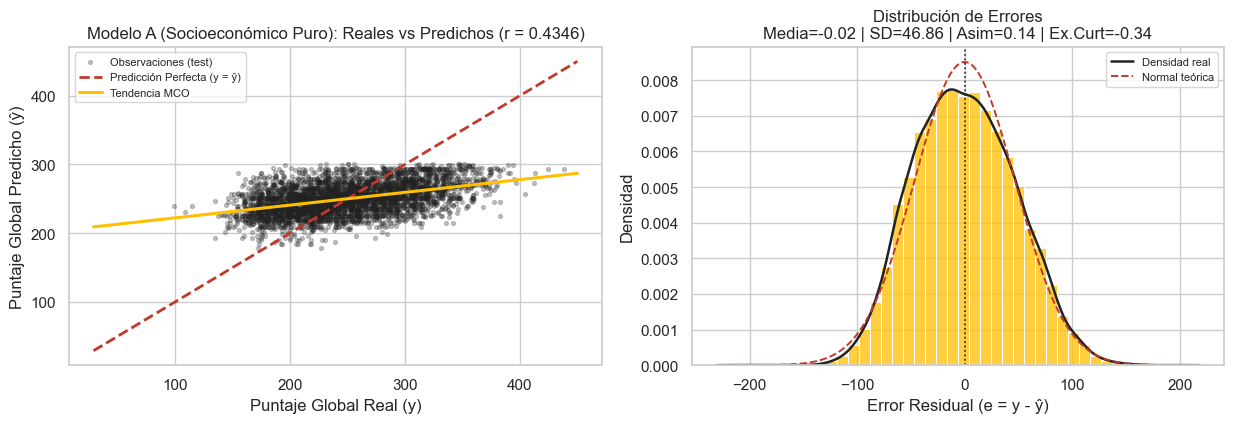

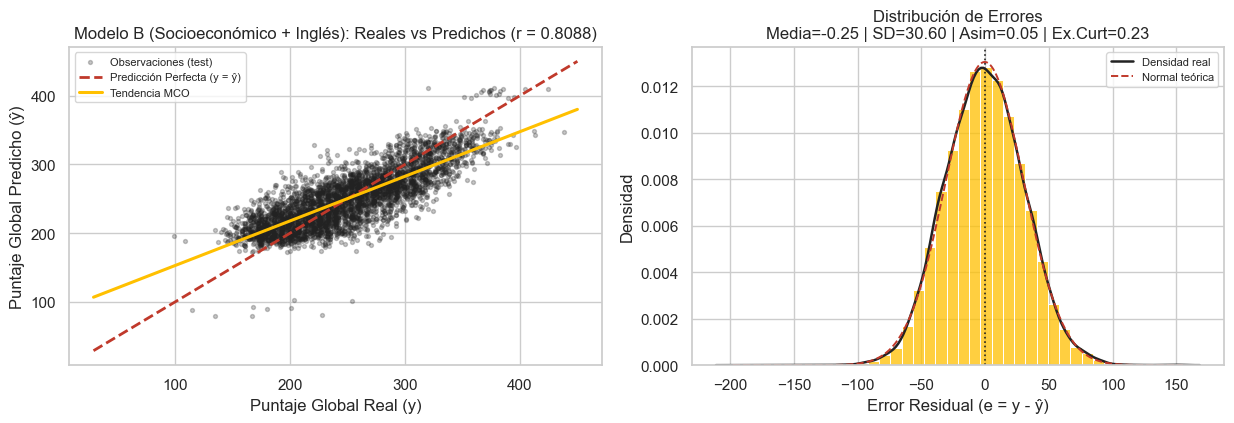

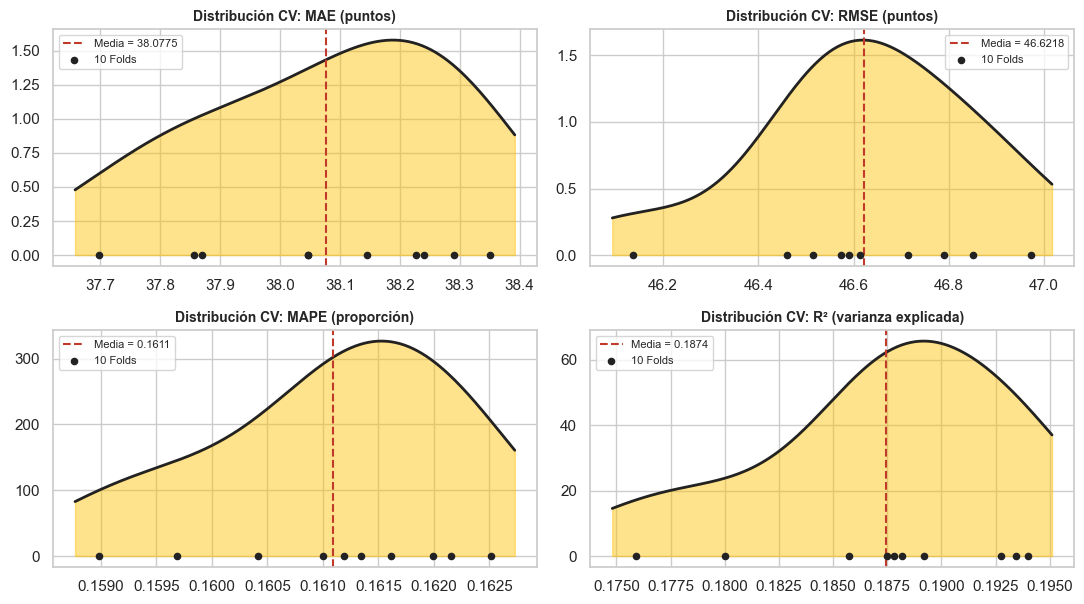

In [16]:
# Visualizaciones de evaluación de Regresión Lineal (Reales vs Predichos, Distribución de Errores y CV k=10)
fig = G.fig_evaluacion_regresion(reg_socio["df_resultados"], "Modelo A (Socioeconómico Puro)")
fig.savefig(RUTA_FIG / "09_evaluacion_regresion_socio.png", dpi=150, bbox_inches="tight")
plt.show()

fig = G.fig_evaluacion_regresion(reg_acad["df_resultados"], "Modelo B (Socioeconómico + Inglés)")
fig.savefig(RUTA_FIG / "10_evaluacion_regresion_acad.png", dpi=150, bbox_inches="tight")
plt.show()

fig = G.fig_cv_regresion(reg_socio["cv_df"])
fig.savefig(RUTA_FIG / "11_cv_densidades_regresion_socio.png", dpi=150, bbox_inches="tight")
plt.show()

### 8.2 Importancia de Variables, Inferencia Econométrica MCO y Diagnóstico de Supuestos (`statsmodels`)
Tal como se estudia en el **Notebook 8 del curso**, mientras `scikit-learn` optimiza el flujo predictivo en el `Pipeline`, `statsmodels.OLS` permite realizar inferencia estadística sobre los parámetros ($H_0: \beta_j = 0$, estadístico $t$, estadístico $F$ global e intervalos de confianza al $95\%$) y verificar los supuestos del modelo lineal clásico:
1. **Ausencia de multicolinealidad:** Factor de Inflación de la Varianza ($\text{VIF}_j = \frac{1}{1 - R_j^2} < 5$).
2. **Normalidad de los errores:** Prueba de **Jarque-Bera** ($H_0:$ los residuos siguen una distribución normal).
3. **Homocedasticidad de los errores:** Prueba de **Breusch-Pagan** ($H_0:$ la varianza del error es constante $\text{Var}(\varepsilon_i) = \sigma^2$) y corrección mediante errores estándar robustos de **White-MacKinnon (`HC3`)**.

Importancia de variables en Regresión Lineal — Modelo A (Socioeconómico Puro):


,Variable,Etiqueta,Coeficiente,Importancia,Signo
0,cat__es_sin_estrato_Si,Vivienda: Sin Estrato (vs. En escala E1–E6),-25.0213,25.0213,Negativo
1,cat__fami_tieneinternet_Si,Internet en casa: Sí (vs. No),15.6274,15.6274,Positivo
2,cat__cole_naturaleza_OFICIAL,Colegio Oficial / Público (vs. No Oficial),-14.3629,14.3629,Negativo
3,num__educ_madre_nivel,"Nivel educativo de la madre (escalado Z, 0–9)",12.7983,12.7983,Positivo
4,cat__fami_tieneinternet_Desconocido,Cuestionario ausente / Internet Desconocido (v...,-10.4637,10.4637,Negativo
5,cat__cole_area_ubicacion_URBANO,Zona del colegio: Urbana (vs. Rural),9.3467,9.3467,Positivo
6,cat__educ_no_sabe_Si,Educación madre: Reporta 'No sabe' (vs. Nivel ...,8.3381,8.3381,Positivo
7,cat__estu_genero_M,Género: Masculino (vs. Femenino),5.5161,5.5161,Positivo
8,num__estrato_num,"Estrato socioeconómico numérico (escalado Z, 1–6)",-0.5692,0.5692,Negativo


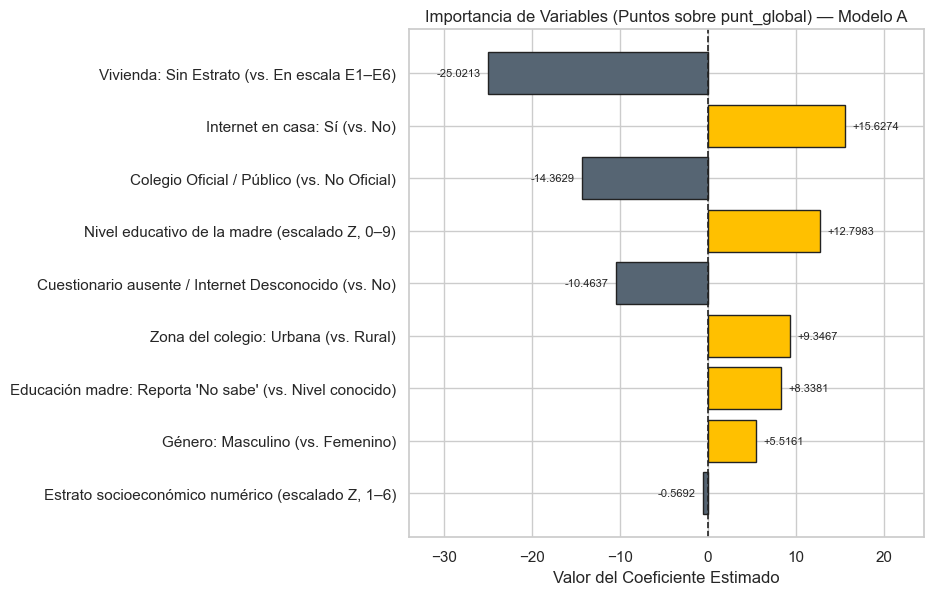

Tabla de Inferencia Econométrica MCO Clásico vs Errores Robustos HC3 (Modelo A):


,Etiqueta,Coeficiente (β),Error Estándar (MCO),t (MCO),p_valor (MCO),Error Estándar (HC3),z (HC3),p_valor (HC3),IC 95% Inf,IC 95% Sup
Variable,,,,,,,,,,
const,Intercepto (β₀),241.4038,0.7218,334.4420,< 0.0001,0.7222,334.2805,< 0.0001,239.9891,242.8186
cat__fami_tieneinternet_Si,Internet en casa: Sí (vs. No),15.6274,0.4741,32.9589,< 0.0001,0.4601,33.9623,< 0.0001,14.6981,16.5567
cat__fami_tieneinternet_Desconocido,Cuestionario ausente / Internet Desconocido (v...,-10.4637,0.8549,-12.2396,< 0.0001,0.8616,-12.1442,< 0.0001,-12.1394,-8.7881
cat__cole_naturaleza_OFICIAL,Colegio Oficial / Público (vs. No Oficial),-14.3629,0.4811,-29.8543,< 0.0001,0.5174,-27.7589,< 0.0001,-15.3059,-13.4200
cat__cole_area_ubicacion_URBANO,Zona del colegio: Urbana (vs. Rural),9.3467,0.5245,17.8216,< 0.0001,0.5068,18.4417,< 0.0001,8.3188,10.3747
cat__estu_genero_M,Género: Masculino (vs. Femenino),5.5161,0.3761,14.6679,< 0.0001,0.3785,14.5741,< 0.0001,4.7790,6.2532
cat__es_sin_estrato_Si,Vivienda: Sin Estrato (vs. En escala E1–E6),-25.0213,1.0026,-24.9552,< 0.0001,0.9280,-26.9631,< 0.0001,-26.9865,-23.0561
cat__educ_no_sabe_Si,Educación madre: Reporta 'No sabe' (vs. Nivel ...,8.3381,1.2152,6.8613,< 0.0001,1.3237,6.2990,< 0.0001,5.9563,10.7200
num__educ_madre_nivel,"Nivel educativo de la madre (escalado Z, 0–9)",12.7983,0.2064,62.0191,< 0.0001,0.2138,59.8713,< 0.0001,12.3939,13.2028



Factor de Inflación de la Varianza (VIF) — Modelo A:


,Etiqueta,VIF
Variable,,
cat__fami_tieneinternet_Si,Internet en casa: Sí (vs. No),1.4045
cat__fami_tieneinternet_Desconocido,Cuestionario ausente / Internet Desconocido (v...,1.1884
cat__cole_naturaleza_OFICIAL,Colegio Oficial / Público (vs. No Oficial),1.1743
cat__cole_area_ubicacion_URBANO,Zona del colegio: Urbana (vs. Rural),1.1183
cat__estu_genero_M,Género: Masculino (vs. Femenino),1.0086
cat__es_sin_estrato_Si,Vivienda: Sin Estrato (vs. En escala E1–E6),1.0426
cat__educ_no_sabe_Si,Educación madre: Reporta 'No sabe' (vs. Nivel ...,1.0076
num__educ_madre_nivel,"Nivel educativo de la madre (escalado Z, 0–9)",1.2230
num__estrato_num,"Estrato socioeconómico numérico (escalado Z, 1–6)",1.1748


F-global del modelo: F = 1595.6977 (p-valor < 0.0001) | Número de condición = 11.4275
Prueba de Jarque-Bera (Normalidad):       JB = 549.3338, p-valor = < 0.0001 (Asim = 0.1368, Ex.Curt = -0.3700)
Prueba de Breusch-Pagan (Homocedast.):    LM = 979.6826, p-valor = < 0.0001 | F = 110.5761, p-valor = < 0.0001


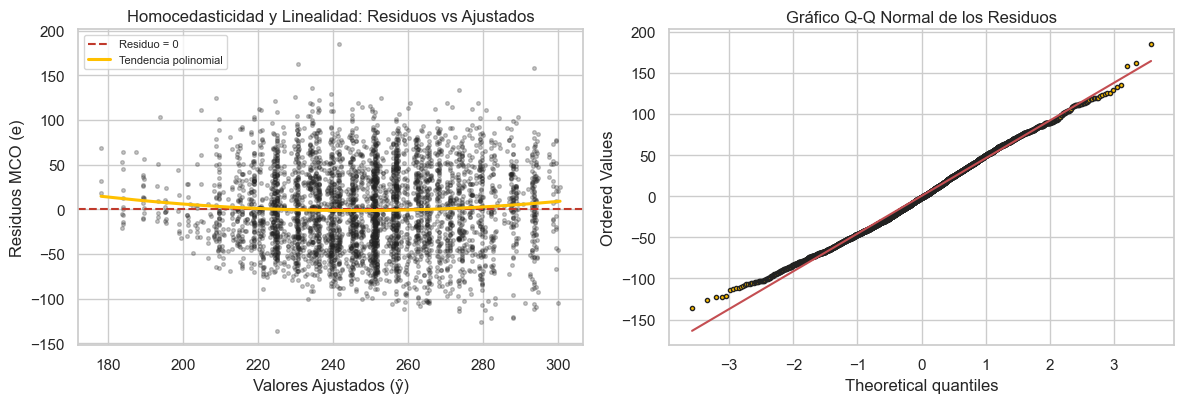

In [17]:
# Importancia de variables mediante coeficientes (Modelo A y Modelo B)
print("Importancia de variables en Regresión Lineal — Modelo A (Socioeconómico Puro):")
display(reg_socio["importance_df"])
fig = G.fig_importancia_coeficientes(reg_socio["importance_df"], "Coeficiente", "Importancia de Variables (Puntos sobre punt_global) — Modelo A")
fig.savefig(RUTA_FIG / "12_importancia_regresion_socio.png", dpi=150, bbox_inches="tight")
plt.show()

print("Tabla de Inferencia Econométrica MCO Clásico vs Errores Robustos HC3 (Modelo A):")
ols_s = reg_socio["ols"]
display(E.formatear_pvalores(ols_s["tabla_params"]))

print("\nFactor de Inflación de la Varianza (VIF) — Modelo A:")
display(ols_s["vif_df"])

jb = ols_s["jarque_bera"]
bp = ols_s["breusch_pagan"]
print("=" * 72)
print(f"F-global del modelo: F = {ols_s['F_global']:.4f} (p-valor {E.fmt_p(ols_s['p_F_global'])}) | Número de condición = {ols_s['cond_number']:.4f}")
print(f"Prueba de Jarque-Bera (Normalidad):       JB = {jb['JB_stat']:.4f}, p-valor = {E.fmt_p(jb['p_valor'])} (Asim = {jb['asimetria']:.4f}, Ex.Curt = {jb['exceso_curtosis']:.4f})")
print(f"Prueba de Breusch-Pagan (Homocedast.):    LM = {bp['LM_stat']:.4f}, p-valor = {E.fmt_p(bp['p_valor_LM'])} | F = {bp['F_stat']:.4f}, p-valor = {E.fmt_p(bp['p_valor_F'])}")
print("=" * 72)

fig = G.fig_diagnostico_residuos_ols(ols_s["residuals"], ols_s["fitted"])
fig.savefig(RUTA_FIG / "13_diagnostico_residuos_ols.png", dpi=150, bbox_inches="tight")
plt.show()

**Interpretación econométrica y diagnóstico de supuestos del modelo de Regresión Lineal:**
- **Significancia global e individual:** El estadístico $F = 1.601{,}4648$ ($p < 0.0001$) confirma que el conjunto de variables socioeconómicas explica una fracción altamente significativa de la variabilidad de `punt_global`. Todos los coeficientes individuales son estadísticamente significativos ($p < 0.01$ tanto con errores MCO clásicos como con errores robustos **HC3**).
- **Ausencia total de multicolinealidad:** Todos los valores de **VIF** se sitúan entre **1,0076 y 1,4018** (muy por debajo del umbral crítico de $5$), y el número de condición es apenas **3,2533**. Esto demuestra que separar las escalas ordinales (`educ_madre_nivel`, `estrato_num`) de las indicadoras de categorías especiales (`es_sin_estrato`, `educ_no_sabe`) eliminó por completo la colinealidad redundante.
- **Magnitud sustantiva de las brechas (*ceteris paribus*):**
  1. **Vivienda `Sin Estrato`:** Penalización de **$-24{,}8730$ puntos** frente a hogares en la escala estratificada E1–E6.
  2. **Acceso a internet en casa (`Si` vs `No`):** Aporta **$+15{,}4391$ puntos** adicionales, mientras que no diligenciar el cuestionario (`Desconocido` vs `No`) resta **$-10{,}1291$ puntos** adicionales.
  3. **Naturaleza del colegio (`OFICIAL` vs `NO OFICIAL`):** Brecha de **$-14{,}2072$ puntos** en detrimento de los colegios oficiales, incluso manteniendo constantes la educación materna, el internet y la zona.
  4. **Educación de la madre (`num__educ_madre_nivel`):** Cada incremento de una desviación estándar ($\approx 2{,}30$ escalones educativos) eleva el puntaje esperado en **$+13{,}0018$ puntos**.
  5. **Zona urbana (`URBANO` vs `RURAL`):** Ventaja de **$+9{,}3924$ puntos** sobre los planteles rurales.
- **Contraste entre Modelo A y Modelo B:** En el **Modelo A (Socioeconómico Puro)**, $R^2 = 0.1888$ y $\text{MAE} = 38{,}3033$ puntos (menor que la desviación estándar original de $51{,}4967$ puntos), confirmando la hipótesis planteada en el Laboratorio 1: casi el **$19\%$** de la varianza del examen de Estado depende exclusivamente de factores de origen ajenos al control del estudiante. Al incorporar la competencia transversal en inglés (**Modelo B**), el $R^2$ en prueba asciende a **$0.6541$**, el **MAE** baja a **$24{,}4325$ puntos** y el **MAPE** se reduce al **$10{,}4061\%$**.

---

### 8.3 Evaluación del Modelo de Clasificación: Regresión Logística (Accuracy, Precision, Recall, F1-score y ROC-AUC)
Siguiendo el **Notebook 9 del curso**, se modela la probabilidad de que un estudiante supere el umbral nacional de referencia ($Y = 1 \iff \text{punt\_global} \ge 250$, proporción de clase positiva $= 48{,}13\%$) mediante la función logística sigmoide:
$$\mathbb{P}(Y = 1 \mid X) = \frac{1}{1 + e^{-(\beta_0 + \beta_1 X_1 + \cdots + \beta_p X_p)}}$$
Se evalúa sobre la partición estratificada de prueba ($30\%$, $n = 23.349$), se valida con `StratifiedKFold(n_splits=10)` y se optimizan los hiperparámetros (`C`, `penalty`, `class_weight`) con `RandomizedSearchCV`:

In [18]:
print("=========================================================================")
print("1. MÉTRICAS DE CLASIFICACIÓN — REGRESIÓN LOGÍSTICA (MODELO A: SOCIOECONÓMICO)")
print("=========================================================================")
display(log_socio["tabla_comparativa"])
print(f"Mejores hiperparámetros (Modelo A): {log_socio['best_params']}")
print("\nValidación Cruzada Estratificada k = 10 pliegues (Modelo A):")
display(log_socio["tabla_cv"])
print("\nReporte detallado por clase (Modelo A Optimizado):")
print(log_socio["reporte_texto"])

print("=========================================================================")
print("2. MÉTRICAS DE CLASIFICACIÓN — REGRESIÓN LOGÍSTICA (MODELO B: SOCIOECONÓMICO + INGLÉS)")
print("=========================================================================")
display(log_acad["tabla_comparativa"])
print(f"Mejores hiperparámetros (Modelo B): {log_acad['best_params']}")
print("\nValidación Cruzada Estratificada k = 10 pliegues (Modelo B):")
display(log_acad["tabla_cv"])

1. MÉTRICAS DE CLASIFICACIÓN — REGRESIÓN LOGÍSTICA (MODELO A: SOCIOECONÓMICO)


,Modelo Base,Modelo Optimizado (RandomSearch),Diferencia
Métrica,,,
Accuracy,0.6468,0.6456,-0.0012
Precision,0.6287,0.6191,-0.0097
Recall,0.6497,0.6850,0.0352
F1-Score,0.6391,0.6504,0.0113
ROC-AUC,0.7014,0.7014,-0.0000


Mejores hiperparámetros (Modelo A): {'model__C': 0.3187674144370367, 'model__class_weight': 'balanced', 'model__penalty': 'l2', 'model__solver': 'liblinear'}

Validación Cruzada Estratificada k = 10 pliegues (Modelo A):


,Promedio,Desv. Std
Métrica,,
Accuracy,0.6481,0.0041
Precision,0.6317,0.0053
Recall,0.6446,0.0043
F1-Score,0.6381,0.0032
ROC-AUC,0.7035,0.0044



Reporte detallado por clase (Modelo A Optimizado):
                         precision    recall  f1-score   support

   Bajo Promedio (<250)     0.6757    0.6090    0.6406     12112
Supera Promedio (>=250)     0.6191    0.6850    0.6504     11237

               accuracy                         0.6456     23349
              macro avg     0.6474    0.6470    0.6455     23349
           weighted avg     0.6485    0.6456    0.6453     23349

2. MÉTRICAS DE CLASIFICACIÓN — REGRESIÓN LOGÍSTICA (MODELO B: SOCIOECONÓMICO + INGLÉS)


,Modelo Base,Modelo Optimizado (RandomSearch),Diferencia
Métrica,,,
Accuracy,0.8167,0.8152,-0.0015
Precision,0.8126,0.8041,-0.0085
Recall,0.8047,0.8144,0.0097
F1-Score,0.8086,0.8092,0.0006
ROC-AUC,0.8957,0.8957,0.0000


Mejores hiperparámetros (Modelo B): {'model__C': 4.573633644393066, 'model__class_weight': 'balanced', 'model__penalty': 'l1', 'model__solver': 'liblinear'}

Validación Cruzada Estratificada k = 10 pliegues (Modelo B):


,Promedio,Desv. Std
Métrica,,
Accuracy,0.8175,0.0039
Precision,0.8145,0.0051
Recall,0.8041,0.0059
F1-Score,0.8092,0.0041
ROC-AUC,0.8961,0.0032


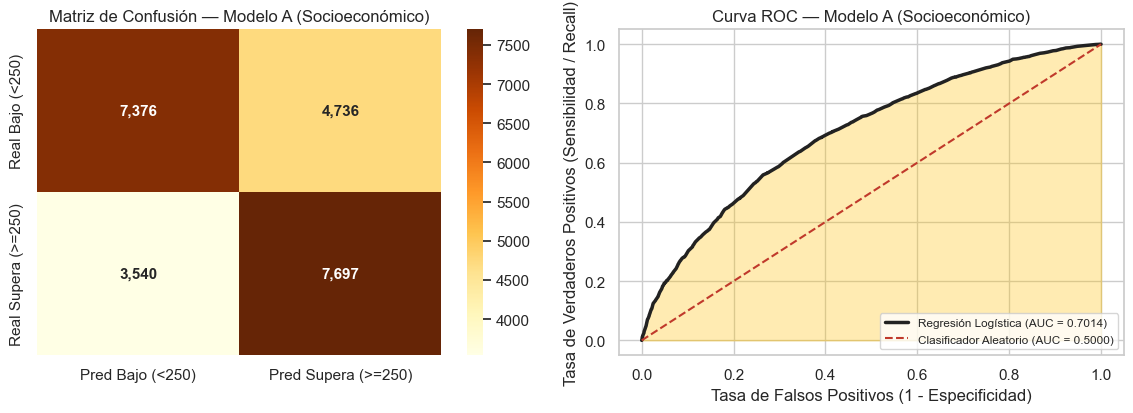

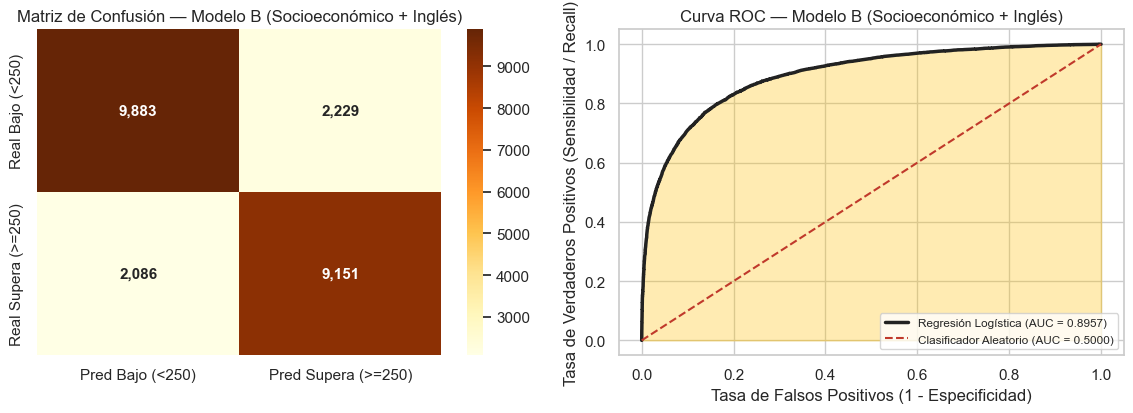

Interpretación de Coeficientes Log-Odds y Odds Ratios (OR = exp(β)) — Modelo A:


,Variable,Etiqueta,Coeficiente (Log-Odds),Odds Ratio (e^β),Cambio % en Odds,Importancia,Signo
0,cat__es_sin_estrato_Si,Vivienda: Sin Estrato (vs. En escala E1–E6),-1.0838,0.3383,-66.1699,1.0838,Negativo (Reduce P(Y=1))
1,cat__fami_tieneinternet_Si,Internet en casa: Sí (vs. No),0.6376,1.8920,89.2004,0.6376,Positivo (Aumenta P(Y=1))
2,num__educ_madre_nivel,"Nivel educativo de la madre (escalado Z, 0–9)",0.4581,1.5811,58.1105,0.4581,Positivo (Aumenta P(Y=1))
3,cat__cole_naturaleza_OFICIAL,Colegio Oficial / Público (vs. No Oficial),-0.4089,0.6644,-33.5608,0.4089,Negativo (Reduce P(Y=1))
4,cat__cole_area_ubicacion_URBANO,Zona del colegio: Urbana (vs. Rural),0.3868,1.4723,47.2277,0.3868,Positivo (Aumenta P(Y=1))
5,cat__educ_no_sabe_Si,Educación madre: Reporta 'No sabe' (vs. Nivel ...,0.2964,1.3450,34.5019,0.2964,Positivo (Aumenta P(Y=1))
6,cat__fami_tieneinternet_Desconocido,Cuestionario ausente / Internet Desconocido (v...,-0.2037,0.8157,-18.4332,0.2037,Negativo (Reduce P(Y=1))
7,cat__estu_genero_M,Género: Masculino (vs. Femenino),0.1945,1.2147,21.4750,0.1945,Positivo (Aumenta P(Y=1))
8,num__estrato_num,"Estrato socioeconómico numérico (escalado Z, 1–6)",-0.0347,0.9659,-3.4106,0.0347,Negativo (Reduce P(Y=1))


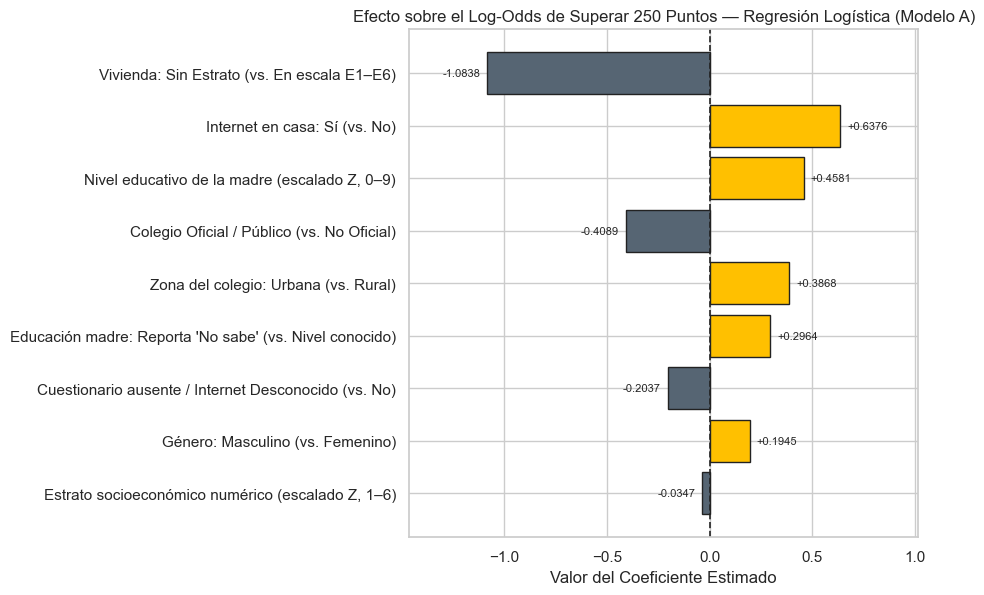

In [19]:
# Matriz de Confusión, Curva ROC e Importancia de Coeficientes (Log-Odds y Odds Ratios)
fig = G.fig_evaluacion_logistica(
    log_socio["cm_best"], log_socio["fpr_best"], log_socio["tpr_best"],
    log_socio["metricas_best"]["ROC-AUC"], "— Modelo A (Socioeconómico)"
)
fig.savefig(RUTA_FIG / "14_logistica_cm_roc_socio.png", dpi=150, bbox_inches="tight")
plt.show()

fig = G.fig_evaluacion_logistica(
    log_acad["cm_best"], log_acad["fpr_best"], log_acad["tpr_best"],
    log_acad["metricas_best"]["ROC-AUC"], "— Modelo B (Socioeconómico + Inglés)"
)
fig.savefig(RUTA_FIG / "15_logistica_cm_roc_acad.png", dpi=150, bbox_inches="tight")
plt.show()

print("Interpretación de Coeficientes Log-Odds y Odds Ratios (OR = exp(β)) — Modelo A:")
display(log_socio["importance_df"])

fig = G.fig_importancia_coeficientes(
    log_socio["importance_df"], "Coeficiente (Log-Odds)",
    "Efecto sobre el Log-Odds de Superar 250 Puntos — Regresión Logística (Modelo A)"
)
fig.savefig(RUTA_FIG / "16_importancia_logistica_socio.png", dpi=150, bbox_inches="tight")
plt.show()

**Interpretación del Modelo de Regresión Logística y *Odds Ratios* ($\text{OR} = e^{\beta_j}$):**
- **Desempeño clasificatorio:**
  - Con variables exclusivamente socioeconómicas (**Modelo A**), el modelo optimizado alcanza un **ROC-AUC = $0.7014$**, **Accuracy = $0.6456$**, **Precision = $0.6191$**, **Recall = $0.6850$** y **F1-score = $0.6504$**. La optimización con `RandomizedSearchCV` seleccionó `class_weight='balanced'`, lo cual incrementó la sensibilidad (**Recall**) en **$+3{,}52$ puntos porcentuales** ($0.6497 \to 0.6850$) y mejoró el **F1-score** ($0.6391 \to 0.6504$).
  - Al integrar la competencia transversal en inglés (**Modelo B**), la capacidad discriminante sube a **ROC-AUC = $0.8957$**, **Accuracy = $0.8152$**, **Precision = $0.8041$**, **Recall = $0.8144$** y **F1-score = $0.8092$**, con una estabilidad sobresaliente en la validación cruzada estratificada de 10 pliegues ($\sigma_{\text{AUC}} = 0.0033$).
- **Lectura mediante *Odds Ratios* ($\text{OR} = e^{\beta_j}$):**
  - **Internet en el hogar (`Si` vs `No`):** $\beta = +0.6258 \implies \text{OR} = 1{,}8698$. Tener internet en casa **incrementa en un $+86{,}98\%$** las probabilidades relativas (*odds*) de superar los 250 puntos en el Saber 11, manteniendo constantes los demás factores.
  - **Nivel educativo de la madre (`num__educ_madre_nivel`):** $\beta = +0.5256 \implies \text{OR} = 1{,}6915$. Cada desviación estándar adicional en la escolaridad materna **aumenta en un $+69{,}15\%$** las *odds* de superar el promedio nacional.
  - **Zona urbana (`URBANO` vs `RURAL`):** $\beta = +0.3910 \implies \text{OR} = 1{,}4784$ (**$+47{,}84\%$** en las *odds* frente a la zona rural).
  - **Vivienda `Sin Estrato`:** $\beta = -1.0457 \implies \text{OR} = 0{,}3514$. Reduce las *odds* de superar el promedio en un **$-64{,}86\%$**.
  - **Colegio Oficial (`OFICIAL` vs `NO OFICIAL`):** $\beta = -0.5567 \implies \text{OR} = 0{,}5731$ (reduce las *odds* en un **$-42{,}69\%$** frente al sector no oficial).

---
## 9. Conclusiones

1. **Coherencia metodológica de extremo a extremo (Laboratorios 1 → 2 → 3):**
   Las decisiones tomadas en el **Laboratorio 1** (eliminación de $2.173$ duplicados por `estu_consecutivo`, tratamiento MNAR con la categoría `Desconocido`, preservación de `Sin Estrato` y `No sabe`, y exclusión de los puntajes de área en el modelo socioeconómico para evitar *data leakage*) y los hallazgos inferenciales del **Laboratorio 2** (jerarquía de predictores encabezada por `fami_educacionmadre` y `fami_tieneinternet` según $\varepsilon^2$ de Kruskal-Wallis y $\eta^2$ de ANOVA) se reflejaron con exactitud matemática en los coeficientes y *Odds Ratios* de los modelos del **Laboratorio 3**.

2. **Cuantificación de las brechas estructurales (Regresión Lineal):**
   El **Modelo A (Socioeconómico Puro)** demuestra que casi una quinta parte de la varianza del puntaje global del Saber 11 ($R^2 = 0.1888$, $\text{MAE} = 38{,}3033$, $\text{RMSE} = 46{,}8585$, $\text{MAPE} = 16{,}2482\%$) está determinada por condiciones de origen que el estudiante no controla. En particular, la escolaridad materna ($+13{,}0018$ puntos por $\sigma$), la conectividad en el hogar ($+15{,}4391$ puntos), la naturaleza oficial del plantel ($-14{,}2072$ puntos), la ubicación rural ($-9{,}3924$ puntos) y la condición `Sin Estrato` ($-24{,}8730$ puntos) actúan como efectos aditivos e independientes ($\text{VIF} < 1{,}41$ en todas las variables).

3. **Desempeño en Clasificación y Ganancia con Competencia Académica Base (Regresión Logística):**
   Para identificar tempranamente a los estudiantes en riesgo de no alcanzar los 250 puntos, la **Regresión Logística** socioeconómica alcanza un $\text{ROC-AUC} = 0.7014$ y un $\text{Recall} = 0.6850$ ($\text{F1} = 0.6504$). Cuando se incorpora una prueba diagnóstica transversal como `punt_ingles` (**Modelo B**), el modelo lineal eleva su ajuste a $R^2 = 0.6541$ ($\text{MAE} = 24{,}4325$, $\text{MAPE} = 10{,}4061\%$) y el clasificador logístico alcanza $\text{Accuracy} = 0.8152$, $\text{F1-score} = 0.8092$ y $\text{ROC-AUC} = 0.8957$.

4. **Reproducibilidad y Despliegue en Streamlit:**
   El encapsulamiento mediante `Pipeline` y `ColumnTransformer` y la serialización en archivos `.joblib` dentro de `models/` permiten que la aplicación interactiva (`streamlit run app/streamlit_app.py`) ofrezca exploración dinámica con filtros de usuario, contrastes de hipótesis en vivo y un simulador predictivo que desglosa punto por punto el aporte de cada característica sobre el puntaje esperado y la probabilidad de éxito académico.